In [1]:
# Setup: libraries and settings (runs for anyone: no Google Drive needed)
import os, sys, glob, json, math, numpy as np, torch, torch.nn.functional as F, matplotlib.pyplot as plt, h5py, cv2
torch.manual_seed(0); np.random.seed(0)
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
DATA_ROOT = os.environ.get('DATA_ROOT', '/content' if os.path.isdir('/content') else os.getcwd())   # where the .emd folder gets unzipped
CURATED = {'mixed alloy': {'0111'}}
print('device:', DEV, '| data:', DATA_ROOT)

device: cpu | data: /content


In [2]:
# 1. Download and unzip the mixed alloy .emd files (skipped if already there)
if os.system('gdown --version > /dev/null 2>&1') != 0: os.system('pip -q install gdown')
ZIPS = {'mixed alloy': ('15phzchCUBtWoar-FP8GWnu1E9mTkul_y', 'mixed alloy-20260116T130033Z-3-001.zip', None)}
for folder, (fid, zname, into) in ZIPS.items():
    if os.path.isdir(os.path.join(DATA_ROOT, folder)): continue
    os.system(f'cd "{DATA_ROOT}" && gdown --fuzzy "https://drive.google.com/file/d/{fid}/view?usp=sharing"')
    os.system(f'cd "{DATA_ROOT}" && unzip -q -o "{zname}"' + (f' -d "{into}"' if into else ''))
for folder in ZIPS:
    e = sorted(glob.glob(os.path.join(DATA_ROOT, folder, '*.emd')))
    assert e, f"no .emd files in {os.path.join(DATA_ROOT, folder)}: the download failed (is the zip shared as 'Anyone with the link'?)"
    print(f"{folder}: {len(e)} .emd files")
    print('  image 0111:', [os.path.basename(p) for p in e if os.path.basename(p).startswith('0111')] or 'NOT FOUND')

mixed alloy: 50 .emd files
  image 0111: ['0111 - 20260111 760 kx STEM 131 nm.emd']


In [3]:
# 2. Read the curated HAADF images: raw intensities + nm/px from the file's own metadata
def first_json(text):
    start = text.find('{'); depth = 0
    for i in range(start, len(text)):
        depth += text[i] == '{'; depth -= text[i] == '}'
        if depth == 0: return json.loads(text[start:i + 1])
    raise ValueError('no JSON object in metadata')

def read_emd(path):
    with h5py.File(path, 'r') as f:
        g = f['Data']['Image'][list(f['Data']['Image'].keys())[0]]
        img = np.asarray(g['Data'][()])
        raw = g['Metadata'][()]; raw = raw[:, 0] if raw.ndim > 1 else raw
        meta = first_json(bytes(np.ravel(raw).tolist()).decode('utf-8', 'replace'))
    if img.ndim == 3: img = img[..., 0]                       # (H, W, frames) -> first frame
    fov = meta['Optics']['FullScanFieldOfView']; scan = meta['Scan']['ScanSize']
    nm_x, nm_y = float(fov['x']) / int(scan['width']) * 1e9, float(fov['y']) / int(scan['height']) * 1e9
    return img.astype(np.float32), nm_x, nm_y, str(img.dtype)

RAW = {}
for folder, ids in CURATED.items():
    for p in sorted(glob.glob(os.path.join(DATA_ROOT, folder, '*.emd'))):
        base = os.path.splitext(os.path.basename(p))[0]
        if base[:4] not in ids or ' SI ' in base: continue
        img, nx, ny, dtype = read_emd(p)
        RAW[f'{folder}/{base}'] = dict(img=img, nm=nx, nm_y=ny, dtype=dtype)

print(f"{len(RAW)} curated HAADF images (expected 38)\n")
print(f"{'image':60s} {'size':>11s} {'nm/px':>7s} {'min':>8s} {'max':>8s} {'at max':>7s}")
for k, r in RAW.items():
    im = r['img']; at_max = (im == im.max()).mean()
    print(f"{k[:60]:60s} {im.shape[1]:5d}x{im.shape[0]:<5d} {r['nm']:7.4f} {im.min():8.0f} {im.max():8.0f} {100*at_max:6.2f}%")

# checks
assert len(RAW), "no images found: did Cell 1 unzip into DATA_ROOT?"
assert all(abs(r['nm'] - r['nm_y']) < 1e-6 for r in RAW.values()), "non-square pixels in some image"
sat = [k for k, r in RAW.items() if (r['img'] == r['img'].max()).mean() > 0.001]
print(f"\nCHECK: square pixels in all {len(RAW)} images")
print("CHECK: detector saturation (>0.1% of pixels at the maximum value):", sat or 'none')

1 curated HAADF images (expected 38)

image                                                               size   nm/px      min      max  at max
mixed alloy/0111 - 20260111 760 kx STEM 131 nm                2048x2048   0.0641     6118    27011   0.00%

CHECK: square pixels in all 1 images
CHECK: detector saturation (>0.1% of pixels at the maximum value): none


NM_PER_PX = 0.478

image                                                             size  shrink    min  median    max
mixed alloy/0111 - 20260111 760 kx STEM 131 nm                274x274  x0.134  -0.21    0.10   2.06

CHECK: total brightness kept by shrinking (mixed alloy/0111 - 20260111 760 kx STEM ...): ratio 0.9969


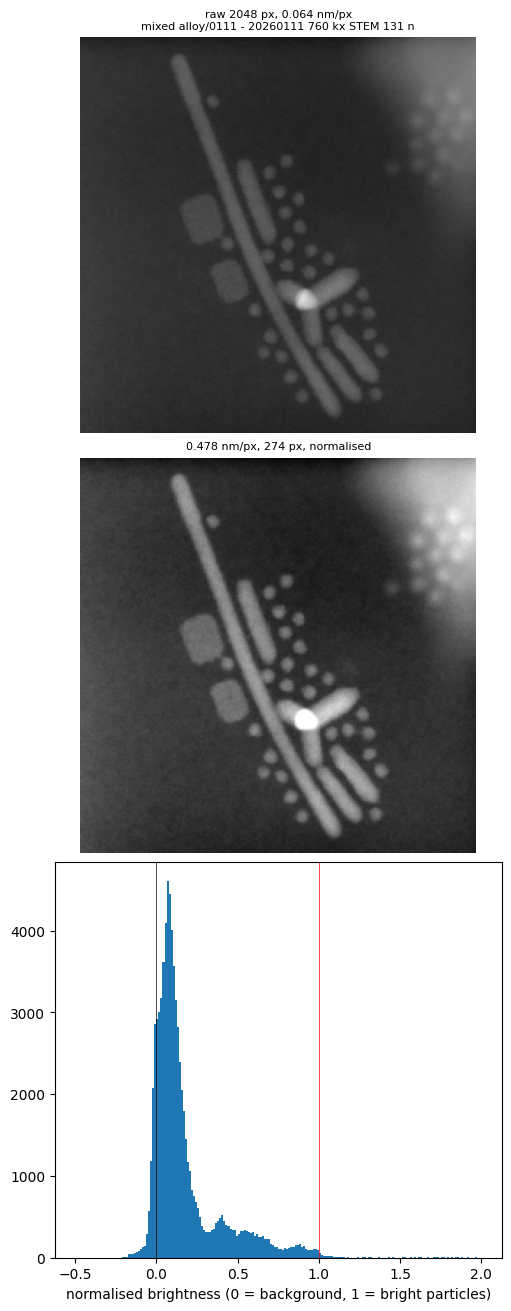

In [5]:
# 3. Bring every image to one scale and one brightness convention

NM_PER_PX = 0.478   # nm per pixel every image is resampled to (the value your earlier Step 1 chose; fixed here so the notebook runs on its own)
print(f"NM_PER_PX = {NM_PER_PX}")

def to_scale(img, nm_from, nm_to):
    # INTER_AREA averages the original pixels inside each new pixel, so total brightness (~ total material) is kept
    f = nm_from / nm_to; H, W = img.shape
    return cv2.resize(img, (max(1, round(W * f)), max(1, round(H * f))), interpolation=cv2.INTER_AREA), f

def normalise(img):
    # background (support film) -> 0, brightest particles -> ~1. No clipping: thicker-than-usual stays above 1.
    smooth = cv2.GaussianBlur(img, (0, 0), 2)
    bg, top = np.percentile(smooth, 10), np.percentile(smooth, 99.5)
    return (img - bg) / (top - bg), bg, top

IMAGES = {}
for k, r in RAW.items():
    small, f = to_scale(r['img'], r['nm'], NM_PER_PX)
    norm, bg, top = normalise(small)
    IMAGES[k] = dict(img=norm.astype(np.float32), factor=f, bg=bg, top=top)

rows = [(k, v['img'].shape, v['factor'], v['img'].min(), np.percentile(v['img'], 50), v['img'].max()) for k, v in IMAGES.items()]
print(f"\n{'image':60s} {'size':>9s} {'shrink':>7s} {'min':>6s} {'median':>7s} {'max':>6s}")
for k, sh, f, mn, med, mx in rows: print(f"{k[:60]:60s} {sh[1]:4d}x{sh[0]:<4d} x{f:5.3f} {mn:6.2f} {med:7.2f} {mx:6.2f}")

# check: shrinking keeps total brightness (sum x pixel area) — it should, to within ~1%
k0 = next(iter(RAW)); f0 = IMAGES[k0]['factor']
small0, _ = to_scale(RAW[k0]['img'], RAW[k0]['nm'], NM_PER_PX)
ratio = small0.sum() / f0**2 / RAW[k0]['img'].sum()
print(f"\nCHECK: total brightness kept by shrinking ({k0[:40]}...): ratio {ratio:.4f}")
assert abs(ratio - 1) < 0.02, "shrinking changed the total brightness"

# look: three images before/after, and their brightness histograms
show = list(IMAGES)[:3]
fig, ax = plt.subplots(3, len(show), figsize=(5 * len(show), 13), constrained_layout=True, squeeze=False)
for j, k in enumerate(show):
    ax[0, j].imshow(RAW[k]['img'], cmap='gray'); ax[0, j].set_title(f"raw {RAW[k]['img'].shape[1]} px, {RAW[k]['nm']:.3f} nm/px\n{k[:45]}", fontsize=8)
    ax[1, j].imshow(IMAGES[k]['img'], cmap='gray', vmin=-0.2, vmax=1.2); ax[1, j].set_title(f"{NM_PER_PX} nm/px, {IMAGES[k]['img'].shape[1]} px, normalised", fontsize=8)
    ax[2, j].hist(IMAGES[k]['img'].ravel(), 200, range=(-0.5, 2)); ax[2, j].axvline(0, color='k', lw=.5); ax[2, j].axvline(1, color='r', lw=.5)
    ax[2, j].set_xlabel('normalised brightness (0 = background, 1 = bright particles)')
    for a in ax[:2, j]: a.axis('off')
plt.show()

automatic choice: 10 whole bright blobs, 3 cut by the crop edge
crop: mixed alloy/0111 - 20260111 760 kx STEM 131 nm  y=18 x=30  128x128 px = 61.2 x 61.2 nm   tensor (1, 1, 128, 128)


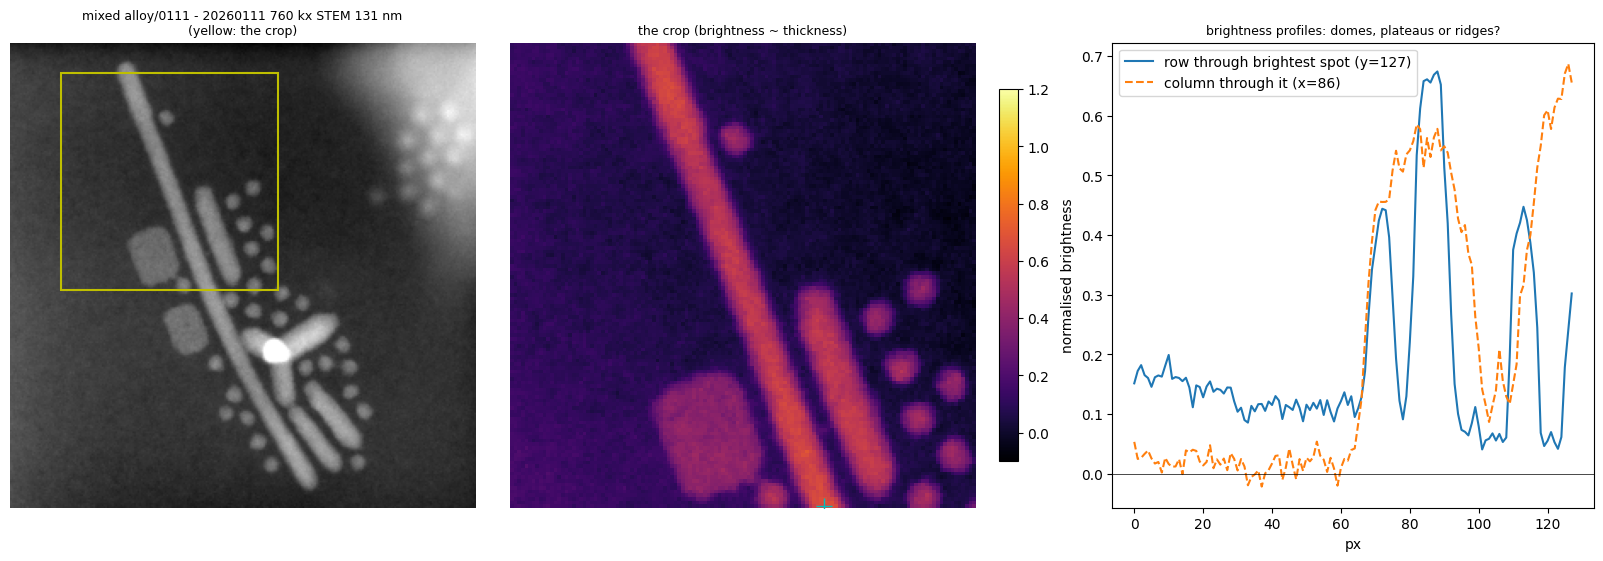

In [6]:
# 4. A small crop with a few particles, used for every picture from here on
CROP_KEY, CROP_Y, CROP_X, CROP = None, None, None, 128      # None = choose automatically; or set your own spot

def count_blobs(img, thr=0.4):
    from scipy import ndimage as ndi
    lab, n = ndi.label(img > thr)
    touches = set(np.unique(np.r_[lab[0], lab[-1], lab[:, 0], lab[:, -1]])) - {0}
    sizes = ndi.sum(np.ones_like(lab), lab, range(1, n + 1))
    whole = [i for i in range(1, n + 1) if i not in touches and sizes[i - 1] >= 8]
    return len(whole), len(touches)

n_particles = 10 # number of particles you want within the selected smaller patch

if CROP_KEY is None:
    best = None
    for k, v in IMAGES.items():
        im = v['img']; H, W = im.shape
        for y in range(0, H - CROP + 1, 6):
            for x in range(0, W - CROP + 1, 6):
                n_whole, n_cut = count_blobs(im[y:y+CROP, x:x+CROP])
                score = -abs(n_whole - n_particles) - 0.5 * n_cut
                if best is None or score > best[0]: best = (score, k, y, x, n_whole, n_cut)
    _, CROP_KEY, CROP_Y, CROP_X, nw, nc = best
    print(f"automatic choice: {nw} whole bright blobs, {nc} cut by the crop edge")
crop = IMAGES[CROP_KEY]['img'][CROP_Y:CROP_Y + CROP, CROP_X:CROP_X + CROP]
X0 = torch.from_numpy(crop)[None, None].to(DEV)               # (1, 1, CROP, CROP): the network's input from now on
print(f"crop: {CROP_KEY}  y={CROP_Y} x={CROP_X}  {CROP}x{CROP} px = {CROP * NM_PER_PX:.1f} x {CROP * NM_PER_PX:.1f} nm   tensor {tuple(X0.shape)}")

fig, ax = plt.subplots(1, 3, figsize=(16, 5.5), constrained_layout=True)
full = IMAGES[CROP_KEY]['img']
ax[0].imshow(full, cmap='gray', vmin=-0.2, vmax=1.2); ax[0].add_patch(plt.Rectangle((CROP_X - .5, CROP_Y - .5), CROP, CROP, fill=False, ec='y', lw=1.5))
ax[0].set_title(f'{CROP_KEY[:50]}\n(yellow: the crop)', fontsize=9)
im = ax[1].imshow(crop, cmap='inferno', vmin=-0.1, vmax=max(1.2, crop.max())); ax[1].set_title('the crop (brightness ~ thickness)', fontsize=9)
plt.colorbar(im, ax=ax[1], shrink=.8)
cy, cx = np.unravel_index(np.argmax(cv2.GaussianBlur(crop, (0, 0), 1)), crop.shape)       # brightest spot
ax[1].plot(cx, cy, '+', c='c', ms=12)
ax[2].plot(crop[cy], label=f'row through brightest spot (y={cy})'); ax[2].plot(crop[:, cx], '--', label=f'column through it (x={cx})')
ax[2].axhline(0, color='k', lw=.5); ax[2].set_xlabel('px'); ax[2].set_ylabel('normalised brightness'); ax[2].legend(); ax[2].set_title('brightness profiles: domes, plateaus or ridges?', fontsize=9)
for a in ax[:2]: a.axis('off')
plt.show()

error = sum |render − truth| / sum truth   (0.05 = 5% of the particle's material misplaced)

         shape       size  err_A_exact_spine  err_B_from_mask  true_halfwidth  found_halfwidth  spine_px
        sphere        r=2              0.000            0.285             2.0         2.000000         3
        sphere        r=4              0.000            0.275             4.0         3.606000         4
        sphere        r=8              0.000            0.077             8.0         7.616000         2
        sphere       r=16              0.000            0.046            16.0        15.556000         2
        sphere       r=30              0.000            0.027            30.0        29.547001         2
   capsule rod  L=10, R=2              0.002            0.207             2.0         2.000000        12
   capsule rod  L=50, R=2              0.003            0.209             2.0         2.000000        52
   capsule rod L=200, R=2              0.003            0.191      

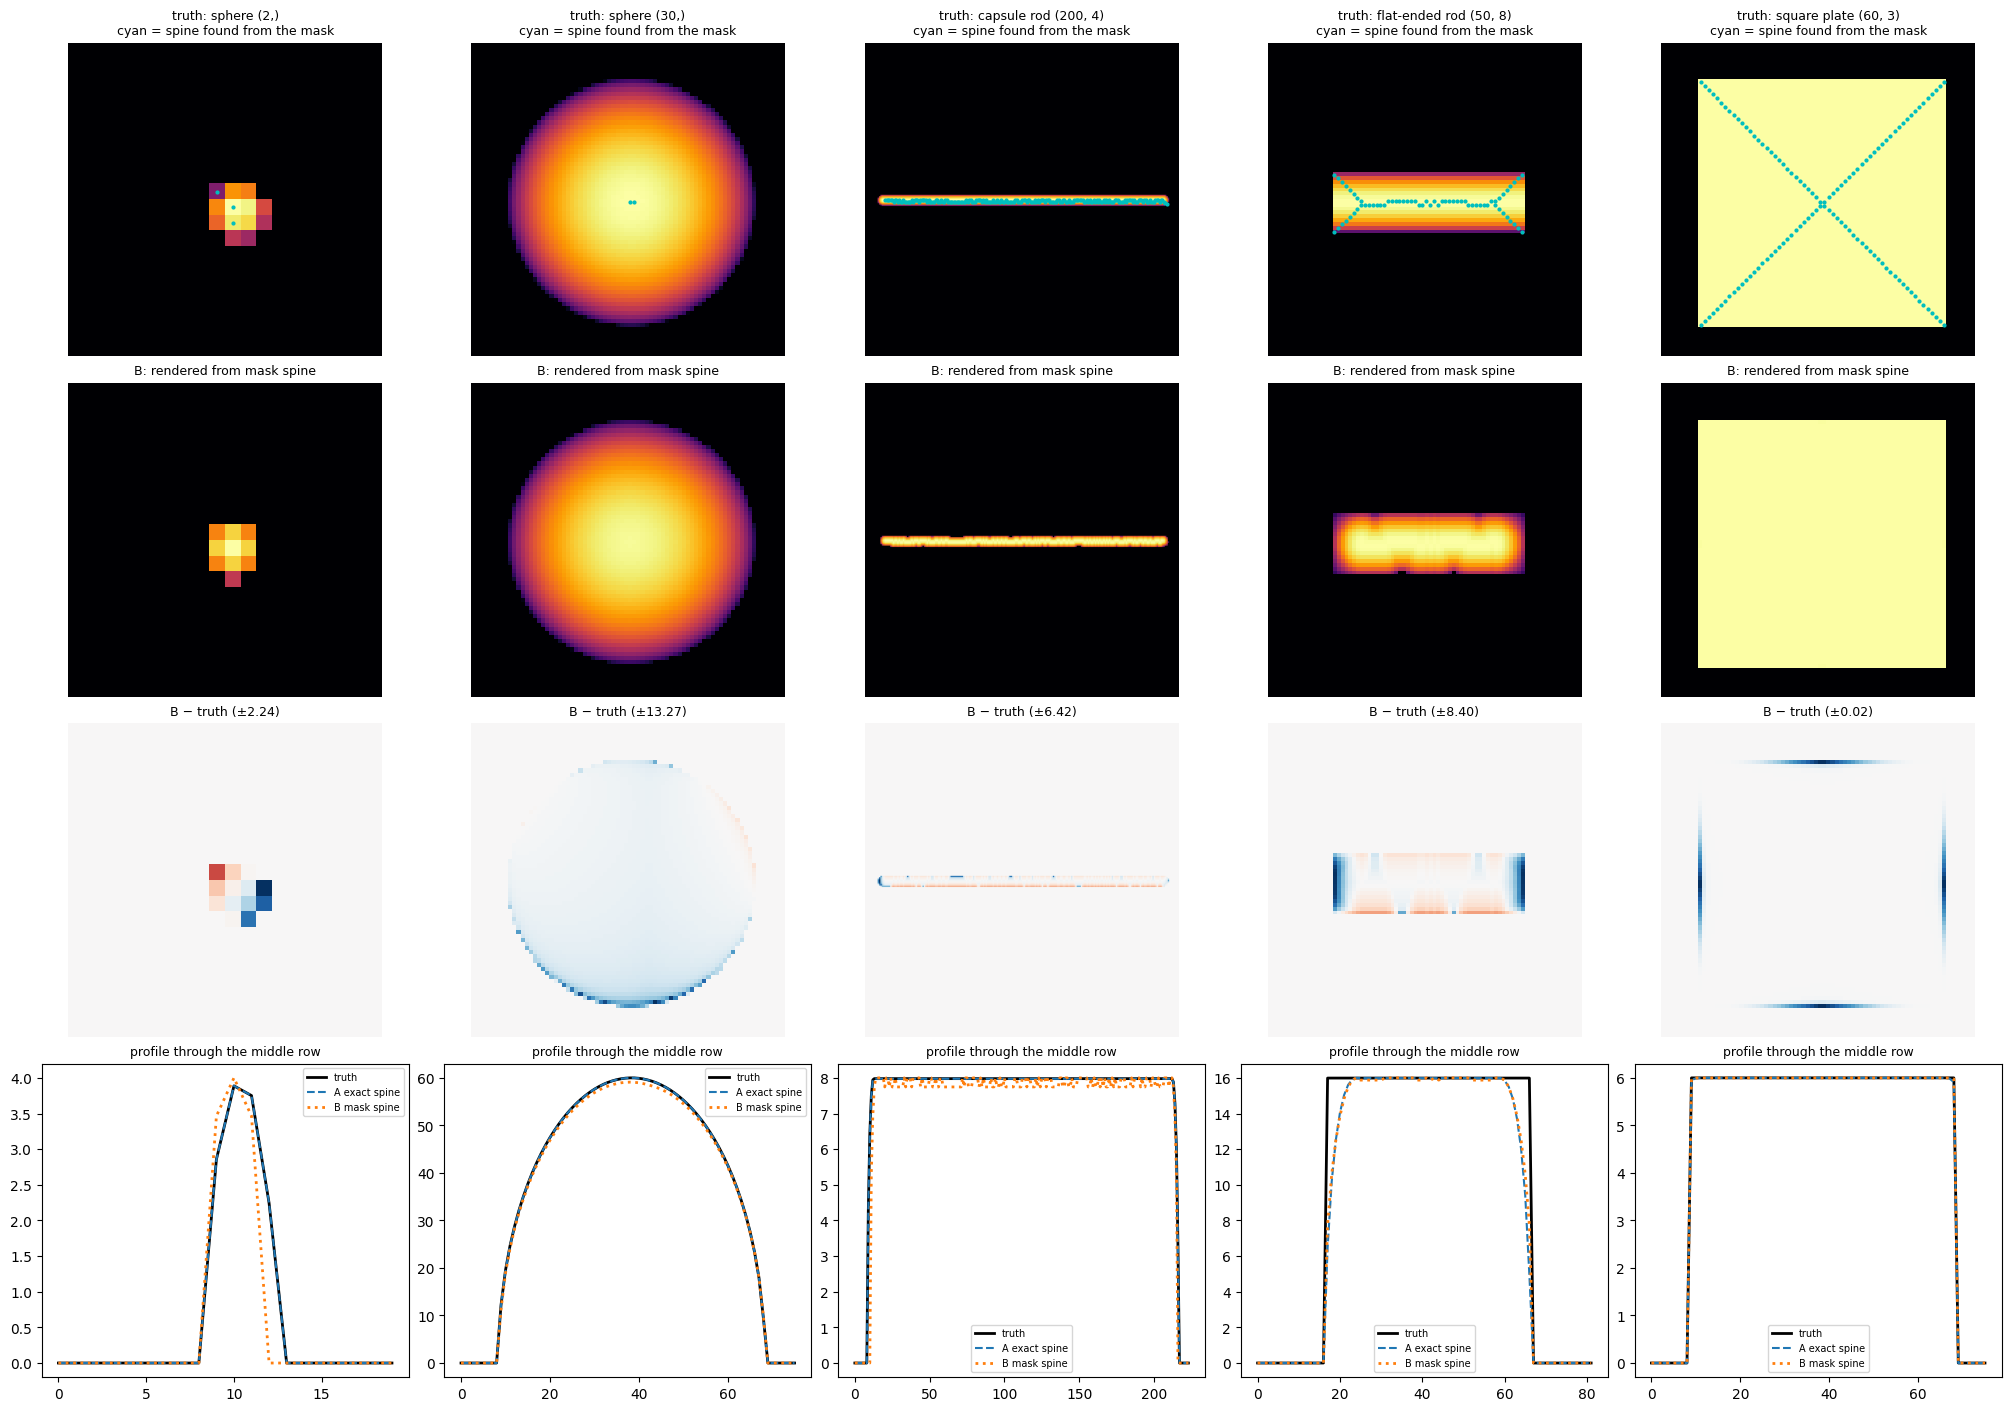

In [17]:
# 5. The core claim, checked at many sizes: "spine + width + thickness, dilated with a 3D profile" = true HAADF projection
from skimage.morphology import medial_axis
import pandas as pd

def bead_profile(t, n):
    # cross-section of one bead, as a fraction of its full thickness, at distance t (in units of its radius) from its centre
    # n = 2: round (dome, like a sphere or cylinder); n large: flat-topped (plateau, like a plate)
    t = np.clip(t, 0, 1); return (1 - t ** n) ** (1 / n)

def render_from_spine(spine, H, W, chunk=256):
    # spine: array of rows (x, y, r, h, n). Thickness at each pixel = MAX over beads of 2h·profile(distance/r).
    # (This loops over spine points: a reference version to check the physics. The fast dense version comes later.)
    yy, xx = np.mgrid[:H, :W].astype(np.float32); out = np.zeros((H, W), np.float32)
    spine = spine[spine[:, 2] > 0]
    for i in range(0, len(spine), chunk):
        s = spine[i:i + chunk]
        d = np.hypot(xx[None] - s[:, 0, None, None], yy[None] - s[:, 1, None, None])
        val = 2 * s[:, 3, None, None] * bead_profile(d / s[:, 2, None, None], s[:, 4, None, None])
        val[d > s[:, 2, None, None]] = 0
        out = np.maximum(out, val.max(0))
    return out

# ---- the true projections (exact formulas), each on its own canvas centred at (cx, cy)
def canvas(extent): n = int(extent + 16); return n, n, n / 2 + 0.37, n / 2 + 0.29   # centre off the pixel grid
def truth(shape, **k):
    if shape == 'sphere':
        H, W, cx, cy = canvas(2 * k['r']); yy, xx = np.mgrid[:H, :W]; d2 = (xx - cx)**2 + (yy - cy)**2
        return 2 * np.sqrt(np.clip(k['r']**2 - d2, 0, None)), (H, W, cx, cy)
    if shape in ('capsule rod', 'flat-ended rod'):
        H, W, cx, cy = canvas(k['L'] + 2 * k['R']); yy, xx = np.mgrid[:H, :W]; u, v = xx - cx, yy - cy
        if shape == 'capsule rod':   # sphere-swept segment (rounded ends)
            du = np.clip(np.abs(u) - k['L'] / 2, 0, None); d2 = du**2 + v**2
            return 2 * np.sqrt(np.clip(k['R']**2 - d2, 0, None)), (H, W, cx, cy)
        inside = np.abs(u) <= k['L'] / 2       # cylinder lying flat, flat ends
        return np.where(inside, 2 * np.sqrt(np.clip(k['R']**2 - v**2, 0, None)), 0), (H, W, cx, cy)
    if shape == 'square plate':
        H, W, cx, cy = canvas(k['S']); yy, xx = np.mgrid[:H, :W]
        inside = (np.abs(xx - cx) <= k['S'] / 2) & (np.abs(yy - cy) <= k['S'] / 2)
        return np.where(inside, 2 * k['h'], 0.0), (H, W, cx, cy)

# ---- A: the spine taken from the exact geometry (tests the renderer alone)
def exact_spine(shape, frame, step=0.25, **k):
    H, W, cx, cy = frame
    if shape == 'sphere': return np.array([[cx, cy, k['r'], k['r'], 2]], np.float32)
    if shape == 'capsule rod':
        u = np.arange(-k['L'] / 2, k['L'] / 2 + 1e-6, step)
        return np.stack([cx + u, np.full_like(u, cy), np.full_like(u, k['R']), np.full_like(u, k['R']), np.full_like(u, 2)], 1).astype(np.float32)
    if shape == 'flat-ended rod':   # medial axis of a rectangle: the axis, plus four branches into the corners
        R, a = k['R'], k['L'] / 2
        u = np.arange(-(a - R), a - R + 1e-6, step); pts = [np.stack([cx + u, np.full_like(u, cy), np.full_like(u, R)], 1)]
        t = np.arange(0, R + 1e-6, step)
        for sx in (-1, 1):
            for sy in (-1, 1):
                pts.append(np.stack([cx + sx * (a - R + t), cy + sy * t, R - t], 1))
        p = np.concatenate(pts); p = p[p[:, 2] > 0.05]                 # drop zero-size beads at the very corners
        return np.c_[p, np.full(len(p), R), np.full(len(p), 2)].astype(np.float32)
    if shape == 'square plate':     # medial axis of a square: its two diagonals; width shrinks to 0 at the corners
        t = np.arange(-k['S'] / 2, k['S'] / 2 + 1e-6, step); pts = []
        for sgn in (1, -1):
            pts.append(np.stack([cx + t, cy + sgn * t, k['S'] / 2 - np.abs(t)], 1))
        p = np.concatenate(pts); p = p[p[:, 2] > 0.05]
        return np.c_[p, np.full(len(p), k['h']), np.full(len(p), 50)].astype(np.float32)

# ---- B: the spine and width found from the pixel mask alone (distance transform), as the network will do it
def spine_from_mask(mask, h_of, n_of):
    skel, dist = medial_axis(mask, return_distance=True)
    ys, xs = np.nonzero(skel); r = np.clip(dist[ys, xs], 0.5, None)      # half-width = distance to the nearest outside pixel
    return np.stack([xs, ys, r, h_of(r), np.full(len(r), n_of)], 1).astype(np.float32)

cases = [('sphere', dict(r=r)) for r in (2, 4, 8, 16, 30)] + \
        [('capsule rod', dict(L=L, R=R)) for R in (2, 4, 8) for L in (10, 50, 200)] + \
        [('flat-ended rod', dict(L=L, R=R)) for R in (2, 4, 8) for L in (20, 50, 200)] + \
        [('square plate', dict(S=S, h=3)) for S in (8, 20, 40, 60)]
rows, gallery = [], {}
for shape, k in cases:
    T, frame = truth(shape, **k); H, W = frame[:2]
    A = render_from_spine(exact_spine(shape, frame, **k), H, W)
    if shape == 'square plate': h_of, n_of = (lambda r: np.full_like(r, k['h'])), 50
    else:                       h_of, n_of = (lambda r: r), 2               # round cross-section: thickness = width
    spB = spine_from_mask(T > 0, h_of, n_of); B = render_from_spine(spB, H, W)
    err = lambda R_: np.abs(R_ - T).sum() / T.sum()
    true_r = k.get('r', k.get('R', k.get('S', 0) / 2))
    rows.append(dict(shape=shape, size=', '.join(f'{a}={b}' for a, b in k.items()), err_A_exact_spine=err(A),
                     err_B_from_mask=err(B), true_halfwidth=true_r, found_halfwidth=spB[:, 2].max(), spine_px=len(spB)))
    gallery[(shape, tuple(k.values()))] = (T, A, B, spB)
res = pd.DataFrame(rows)
pd.set_option('display.width', 200)
print("error = sum |render − truth| / sum truth   (0.05 = 5% of the particle's material misplaced)\n")
print(res.round(3).to_string(index=False))

show = [('sphere', (2,)), ('sphere', (30,)), ('capsule rod', (200, 4)), ('flat-ended rod', (50, 8)), ('square plate', (60, 3))]
fig, ax = plt.subplots(4, len(show), figsize=(4 * len(show), 14), constrained_layout=True)
for j, key in enumerate(show):
    T, A, B, spB = gallery[key]; v = T.max()
    ax[0, j].imshow(T, cmap='inferno', vmin=0, vmax=v); ax[0, j].set_title(f'truth: {key[0]} {key[1]}\ncyan = spine found from the mask', fontsize=9)
    ax[0, j].scatter(spB[:, 0], spB[:, 1], s=4, c='c')
    ax[1, j].imshow(B, cmap='inferno', vmin=0, vmax=v); ax[1, j].set_title('B: rendered from mask spine', fontsize=9)
    l = max(np.abs(B - T).max(), 1e-6); ax[2, j].imshow(B - T, cmap='RdBu_r', vmin=-l, vmax=l); ax[2, j].set_title(f'B − truth (±{l:.2f})', fontsize=9)
    c = T.shape[0] // 2
    ax[3, j].plot(T[c], 'k-', lw=2, label='truth'); ax[3, j].plot(A[c], '--', label='A exact spine'); ax[3, j].plot(B[c], ':', lw=2, label='B mask spine')
    ax[3, j].set_title('profile through the middle row', fontsize=9); ax[3, j].legend(fontsize=7)
    for a in ax[:3, j]: a.axis('off')
plt.show()

background -0.029..0.141 | noise 0.0236 | median edge threshold 0.193 | mask 17.8% of crop | spine 222 px
amp (brightness per px of thickness) = 0.0554 | h/r on the spine: median 1.00, 10-90% 0.69-1.12
rms(crop - drawing) = 0.0519   rms inside particles = 0.0891   pixel noise ≈ 0.0236

12 particles (spine pieces) in the crop:
 id  spine_px      x      y  length_nm  width_nm  thickness_nm  h_over_r  touches_edge
  1       129  62.29  63.98      69.17      4.28          4.35      1.04          True
  4        45  91.00  95.00      27.42      4.87          3.99      0.80         False
  9        22  54.36 109.32      17.99      9.87          2.39      0.23         False
 10         3 122.00 113.00       4.80      3.45          3.14      0.95         False
 11         4  71.75 124.25       4.51      3.16          3.17      0.99         False
  8         4 112.50 102.50       4.30      2.79          3.23      1.16         False
  3         3 113.00  66.00       4.22      2.87          3.15 

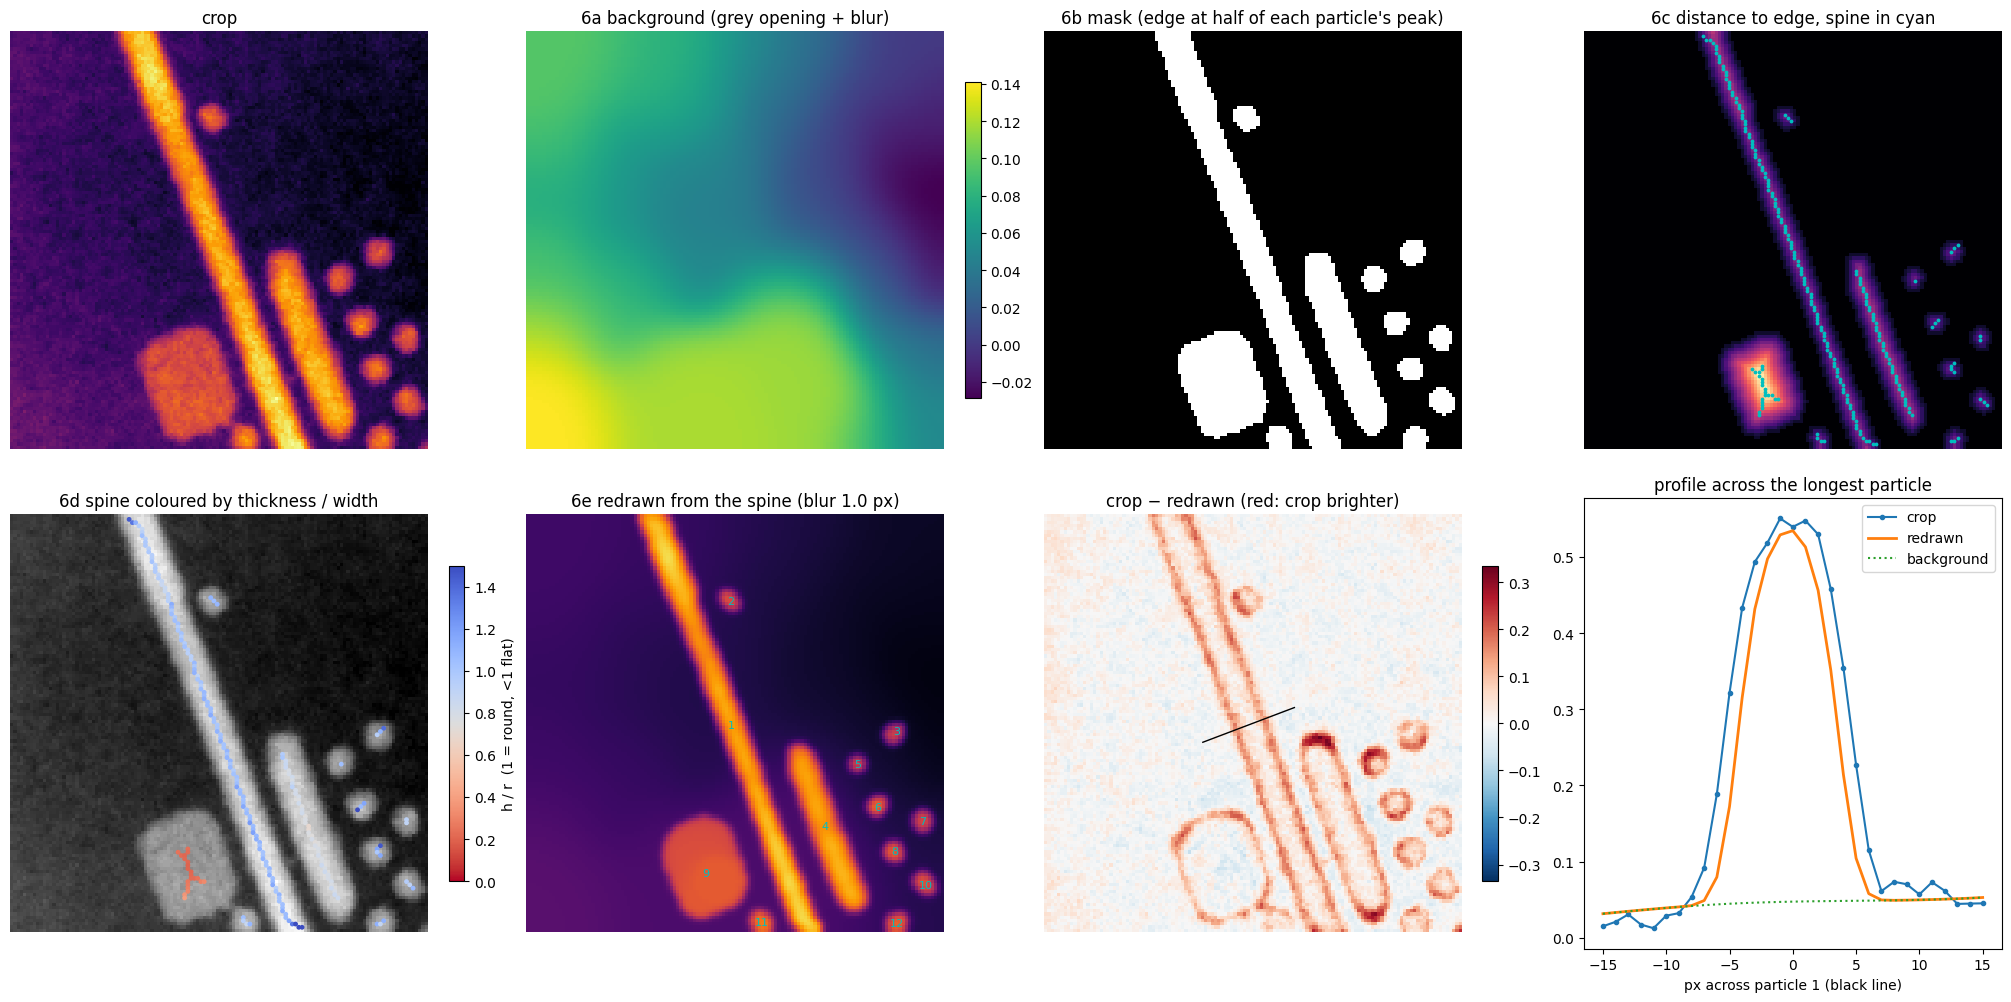

In [18]:
# 6. The spine method on YOUR crop, nothing learned yet: background -> mask -> spine & width -> thickness -> redraw -> particle list
from scipy import ndimage as ndi
import pandas as pd
from skimage.morphology import remove_small_objects, disk, skeletonize
img = X0[0, 0].cpu().numpy().astype(np.float32); H, W = img.shape
BG_SIZE   = 41      # px; must be wider than the widest particle (the plate is ~27 px)
MIN_AREA  = 12      # px; smaller blobs are treated as noise
PLATE_HR  = 0.6     # spine pixels with thickness/width below this are drawn flat-topped (plate), above it round
PSF_SIGMA = 1.0     # px; blur of the electron probe. The image is blurred, so the redraw must be blurred the same way

# ---- 6a. background: what's left after removing everything narrower than BG_SIZE (grey opening), then smoothed
bg = ndi.gaussian_filter(ndi.grey_opening(ndi.gaussian_filter(img, 1), footprint=disk(BG_SIZE // 2)), 6)
noise = np.std(img - ndi.gaussian_filter(img, 1)) * 1.4          # pixel noise (the 1.4 undoes the part removed by the blur)
rough = ndi.gaussian_filter(img - bg, 1) > 4 * noise             # rough particle area, only to correct the background
bg = bg + np.median((img - bg)[~ndi.binary_dilation(rough, iterations=3)])   # opening sits low (it takes minima): lift it
sig = img - bg                                                  # particle signal only

# ---- 6b. particle mask: each particle's edge at HALF its own peak brightness (where a blurred edge really is)
smooth = ndi.gaussian_filter(sig, 1)
low = remove_small_objects(smooth > 4 * noise, min_size=MIN_AREA)       # everything clearly above the noise
lab_low, nlow = ndi.label(low)
peak = ndi.maximum(smooth, lab_low, index=np.arange(1, nlow + 1))        # brightest value of each blob
thr_map = np.r_[np.inf, 0.5 * np.asarray(peak)][lab_low]                # half of its own peak, pixel by pixel
mask = ndi.binary_fill_holes(remove_small_objects(smooth > thr_map, min_size=MIN_AREA))
thr = float(np.median(0.5 * np.asarray(peak)))

# ---- 6c. spine (deterministic thinning) and half-width r = distance to the edge
dist = ndi.distance_transform_edt(mask)
spine_px = skeletonize(mask)
ys, xs = np.nonzero(spine_px); r = np.clip(dist[ys, xs], 0.5, None)

# ---- 6d. thickness from brightness on the spine.  Brightness = amp x thickness, amp unknown (material, detector).
#          Calibrate amp by assuming the MEDIAN spine pixel is round (thickness = width), then thickness everywhere = brightness / amp.
b = smooth[ys, xs]
amp = np.median(b / (2 * r))
h = b / (2 * amp)                                               # half-thickness, px
hr = h / r                                                      # 1 = round cross-section (as thick as wide); < 1 flatter (plate-like)
n = np.where(hr < PLATE_HR, 8.0, 2.0)                           # flat-topped beads for plate-like parts, domes otherwise
spine = np.stack([xs, ys, r, h, n], 1).astype(np.float32)

# ---- 6e. redraw: background + amp x (max over beads), exactly the Cell 5 renderer
drawn = bg + amp * ndi.gaussian_filter(render_from_spine(spine, H, W), PSF_SIGMA)
resid = img - drawn
print(f"background {bg.min():.3f}..{bg.max():.3f} | noise {noise:.4f} | median edge threshold {thr:.3f} | mask {100*mask.mean():.1f}% of crop | spine {len(spine)} px")
print(f"amp (brightness per px of thickness) = {amp:.4f} | h/r on the spine: median {np.median(hr):.2f}, 10-90% {np.percentile(hr, 10):.2f}-{np.percentile(hr, 90):.2f}")
print(f"rms(crop - drawing) = {np.sqrt((resid**2).mean()):.4f}   rms inside particles = {np.sqrt((resid[mask]**2).mean()):.4f}   pixel noise ≈ {noise:.4f}")

# ---- 6f. first particle list: one particle per connected spine piece
lab, npart = ndi.label(spine_px, structure=np.ones((3, 3)))
rows = []
for i in range(1, npart + 1):
    sel = lab[ys, xs] == i
    if sel.sum() < 1: continue
    yy_, xx_ = ys[sel], xs[sel]
    span = np.hypot(np.ptp(xx_), np.ptp(yy_))                 # end-to-end extent of the spine piece
    rows.append(dict(id=i, spine_px=int(sel.sum()), x=xx_.mean(), y=yy_.mean(),
                     length_nm=(span + 2 * np.median(r[sel])) * NM_PER_PX, width_nm=2 * np.median(r[sel]) * NM_PER_PX,
                     thickness_nm=2 * np.median(h[sel]) * NM_PER_PX, h_over_r=np.median(hr[sel]),
                     touches_edge=bool((xx_.min() < 2) | (yy_.min() < 2) | (xx_.max() > W - 3) | (yy_.max() > H - 3))))
parts = pd.DataFrame(rows).sort_values('length_nm', ascending=False)
print(f"\n{len(parts)} particles (spine pieces) in the crop:")
print(parts.round(2).to_string(index=False))

# ---- pictures: every intermediate step
fig, ax = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
v = max(img.max(), drawn.max())
ax[0, 0].imshow(img, cmap='inferno', vmin=-0.05, vmax=v); ax[0, 0].set_title('crop')
im = ax[0, 1].imshow(bg, cmap='viridis'); ax[0, 1].set_title('6a background (grey opening + blur)'); plt.colorbar(im, ax=ax[0, 1], shrink=.7)
ax[0, 2].imshow(mask, cmap='gray'); ax[0, 2].set_title('6b mask (edge at half of each particle\'s peak)')
ax[0, 3].imshow(dist, cmap='magma'); ax[0, 3].scatter(xs, ys, s=3, c='c'); ax[0, 3].set_title('6c distance to edge, spine in cyan')
ax[1, 0].imshow(img, cmap='gray', vmin=-0.05, vmax=v)
sc = ax[1, 0].scatter(xs, ys, s=6, c=hr, cmap='coolwarm_r', vmin=0, vmax=1.5); plt.colorbar(sc, ax=ax[1, 0], shrink=.7, label='h / r  (1 = round, <1 flat)')
ax[1, 0].set_title('6d spine coloured by thickness / width')
ax[1, 1].imshow(drawn, cmap='inferno', vmin=-0.05, vmax=v); ax[1, 1].set_title(f'6e redrawn from the spine (blur {PSF_SIGMA} px)')
l = np.abs(resid).max(); im = ax[1, 2].imshow(resid, cmap='RdBu_r', vmin=-l, vmax=l); ax[1, 2].set_title('crop − redrawn (red: crop brighter)')
plt.colorbar(im, ax=ax[1, 2], shrink=.7)
for _, p in parts.iterrows(): ax[1, 1].text(p.x, p.y, str(int(p.id)), color='c', fontsize=8, ha='center', va='center')
# profile across the longest particle, perpendicular to its spine, through its middle
p = parts.iloc[0]; sel = lab[ys, xs] == p.id
cxy = np.c_[xs[sel], ys[sel]].astype(float); c0 = cxy.mean(0); u, s_, vt = np.linalg.svd(cxy - c0); d = vt[0]; nrm = np.array([-d[1], d[0]])
t = np.arange(-15, 16); px_, py_ = c0[0] + t * nrm[0], c0[1] + t * nrm[1]
samp = lambda a: ndi.map_coordinates(a, [py_, px_], order=1)
ax[1, 2].plot(px_, py_, 'k-', lw=1)
ax[1, 3].plot(t, samp(img), 'o-', ms=3, label='crop'); ax[1, 3].plot(t, samp(drawn), '-', lw=2, label='redrawn'); ax[1, 3].plot(t, samp(bg), ':', label='background')
ax[1, 3].set_xlabel('px across particle %d (black line)' % p.id); ax[1, 3].legend(); ax[1, 3].set_title('profile across the longest particle')
for a in list(ax[0]) + list(ax[1, :3]): a.axis('off')
plt.show()

image 274x274 px, 9 crops of 128x128 px
amp calibrated on the whole image: 0.0452  (used for every crop below)

per crop (amp_if_own = what this crop alone would calibrate to; rms_over_noise ~1 = perfect redraw):
  y   x  particles  whole  amp_if_own  noise  rms_inside  rms_over_noise  plate_like  round_like
  0   0          4      2      0.0549 0.0209      0.0907          4.3353           0           2
  0  96          9      6      0.0501 0.0200      0.0867          4.3306           1           5
  0 146         16     15      0.0134 0.0176      0.0430          2.4437           9           6
 96   0          7      4      0.0568 0.0221      0.0876          3.9719           1           3
 96  96         24     21      0.0554 0.0305      0.1538          5.0394           1          20
 96 146         17     11      0.0590 0.0254      0.1887          7.4336           0          11
146   0          4      2      0.0592 0.0198      0.0828          4.1872           1           1
146  96    

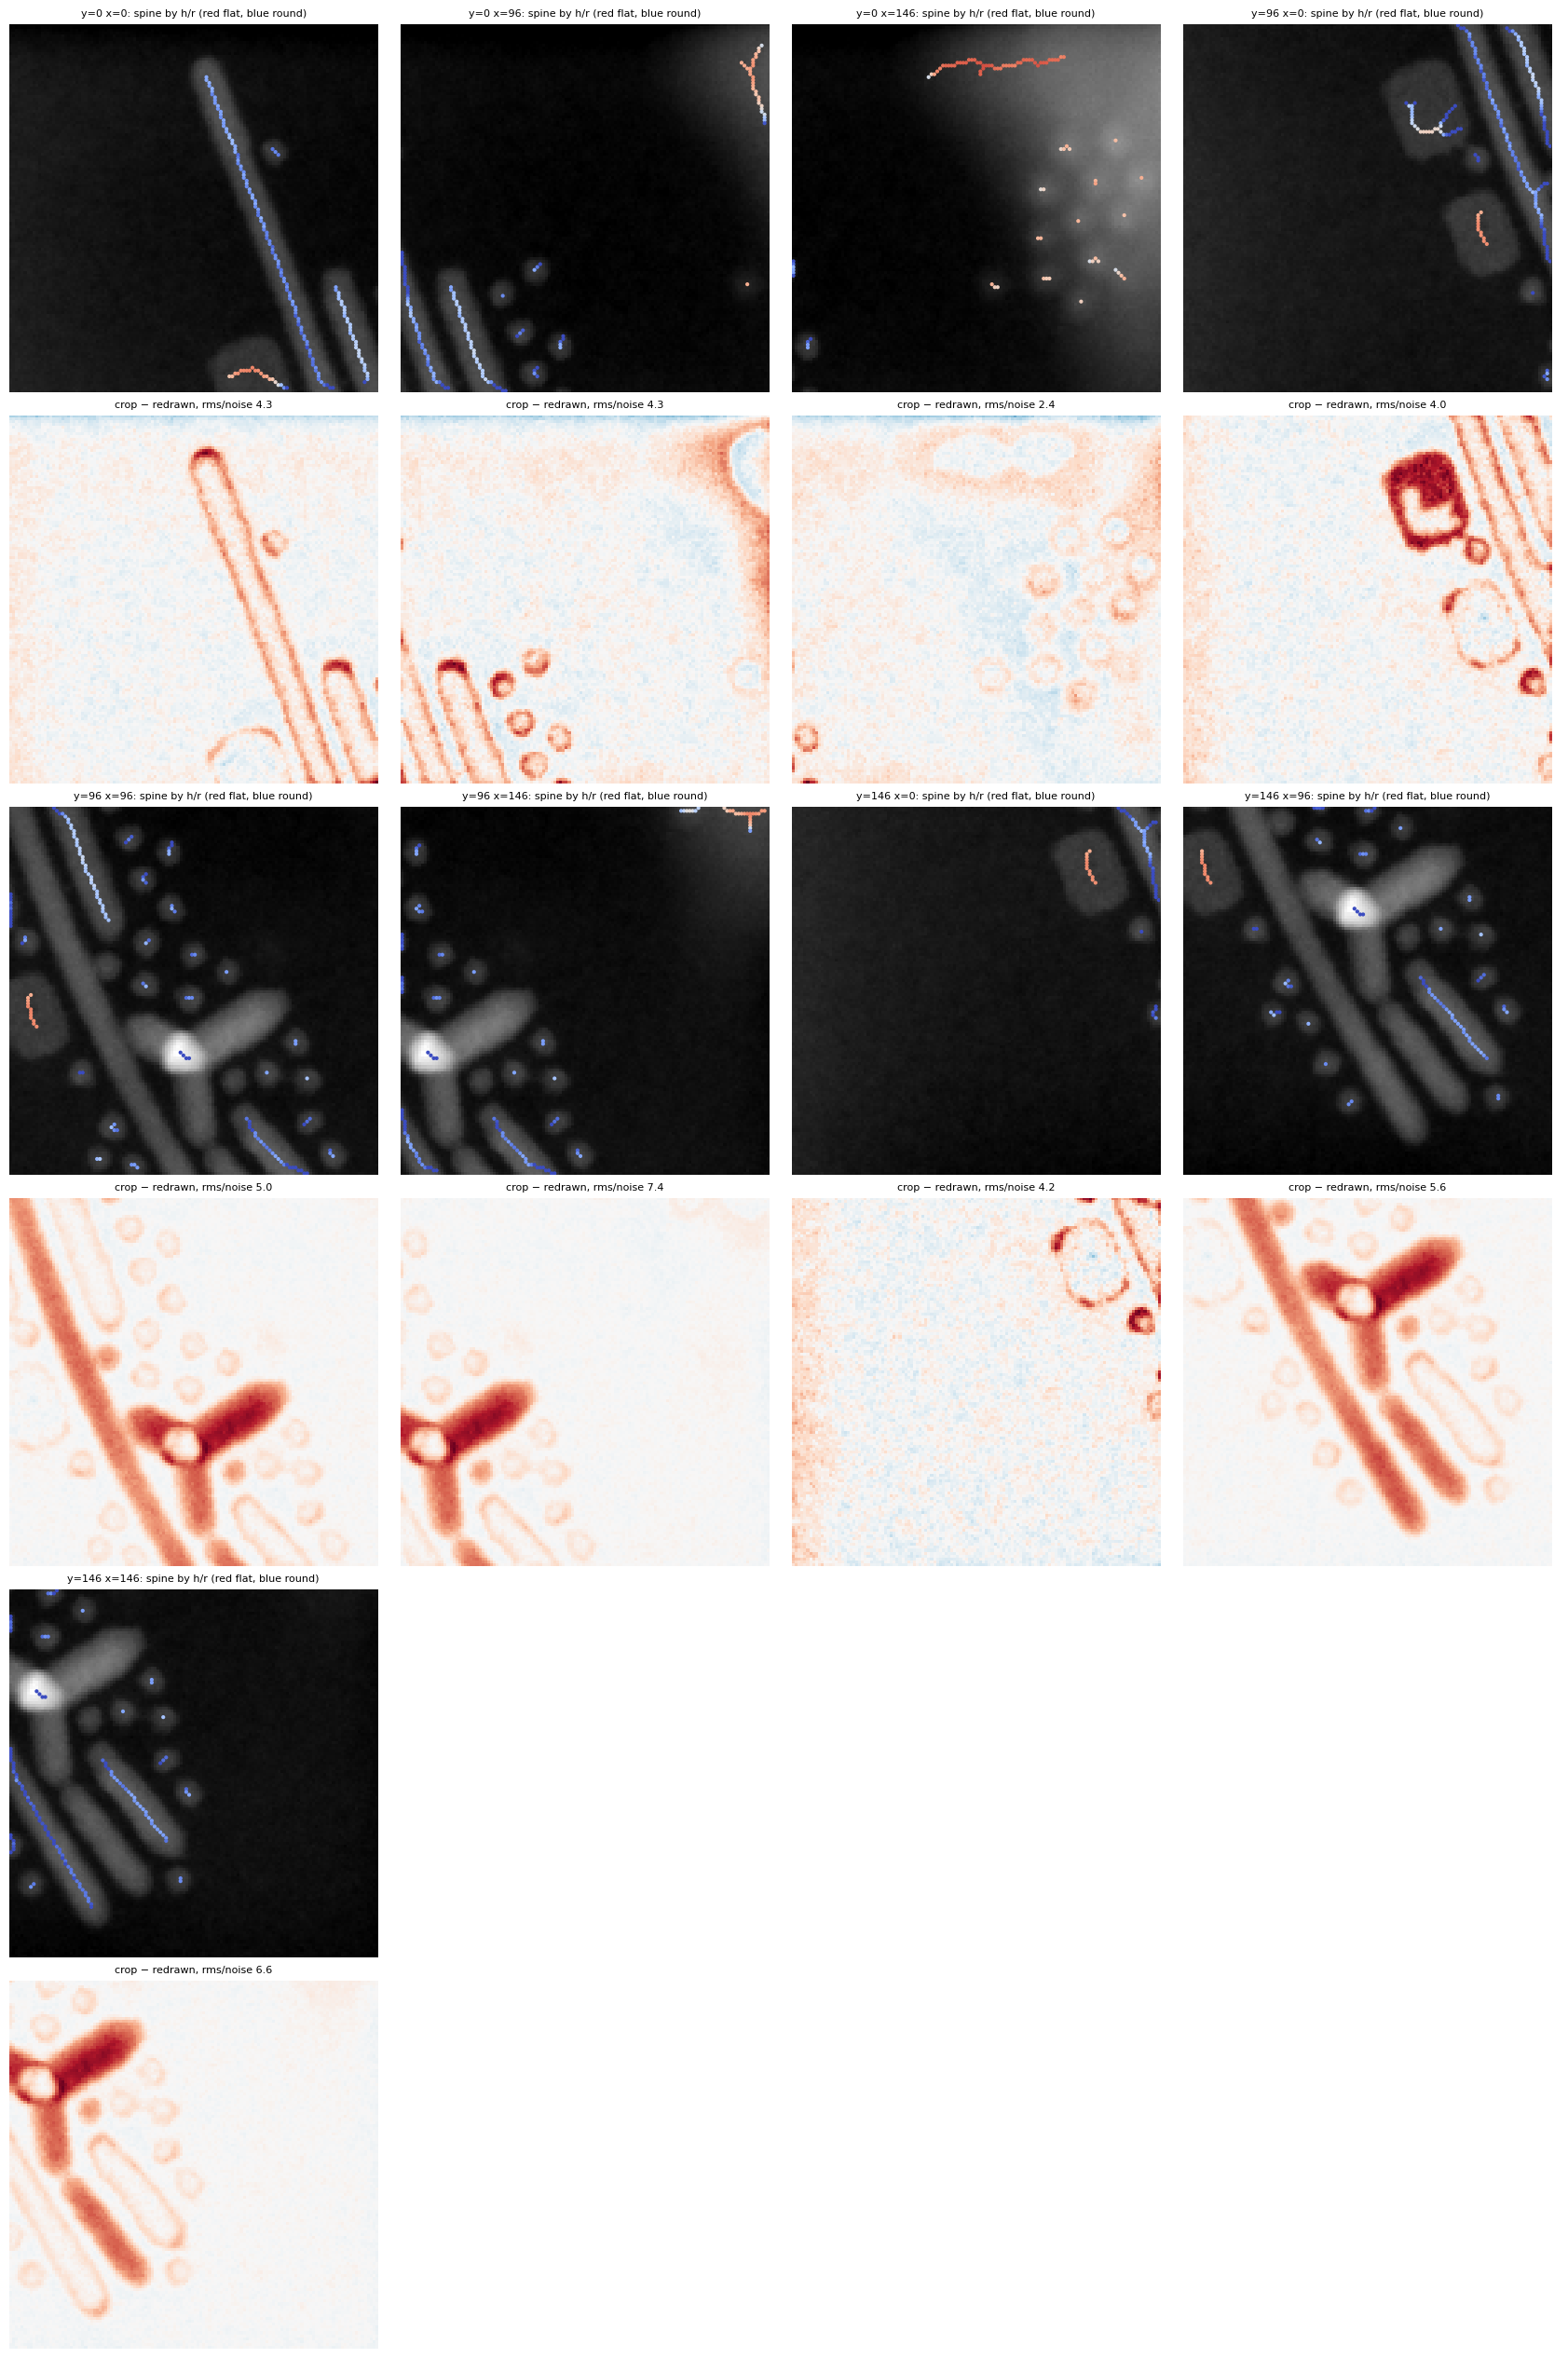


WHOLE IMAGE: 43 particles (42 not touching the edge), amp 0.0452, rms/noise inside 6.03


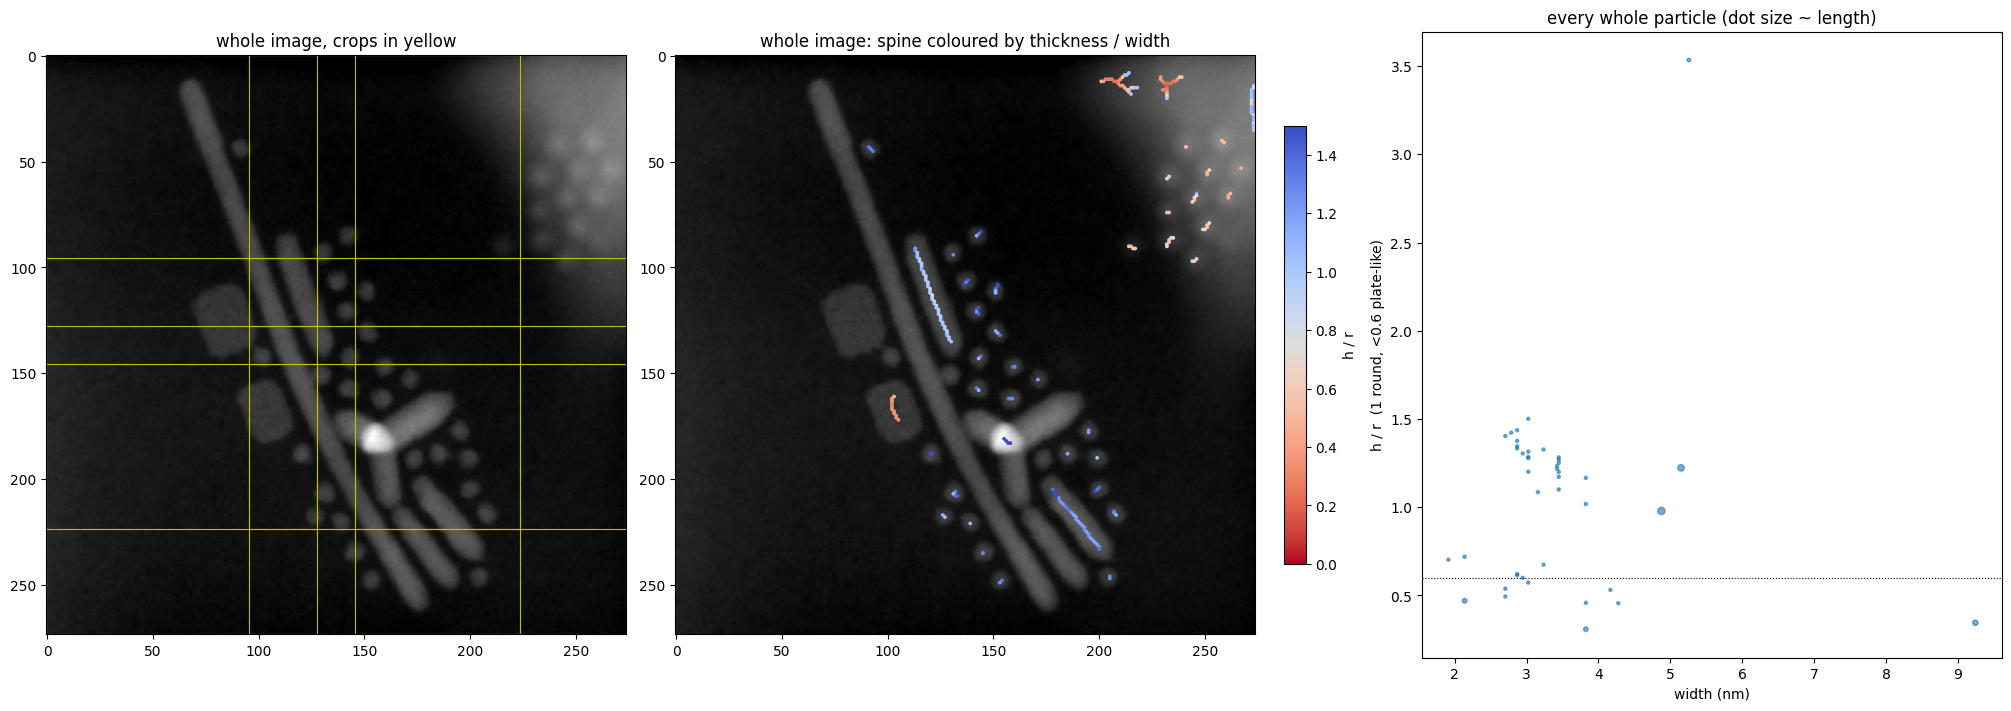

 id  spine_px      x      y  length_nm  width_nm  thickness_nm  h_over_r  touches_edge
 17        45 121.00 113.00      27.42      4.87          4.90      0.98         False
 36        29 189.10 219.00      22.17      5.15          6.28      1.22         False
 28        12 102.83 166.50      14.69      9.24          3.19      0.35         False
  1        26 210.35  12.85      11.57      2.14          1.05      0.47         False
  2        21 232.76  13.86      10.58      3.82          1.12      0.31         False
 31         4 156.50 182.25       6.98      5.26         18.78      3.53         False
 13         5 250.60  80.80       4.90      2.87          1.78      0.62         False
 11         3 261.33  66.00       4.89      3.82          1.62      0.46         False
  4         2 258.50  40.50       4.84      4.17          2.21      0.53         False
 23         3 152.00 131.00       4.80      3.45          3.87      1.17         False
 21         5 151.40 110.00       4.67     

In [19]:
# 7. The Cell 6 method as one function, run on many crops of the whole image (and on the whole image at once)
from scipy import ndimage as ndi
import pandas as pd
from skimage.morphology import remove_small_objects, disk, skeletonize
import warnings; warnings.filterwarnings('ignore', category=FutureWarning)

def spine_analysis(img, amp=None, BG_SIZE=41, MIN_AREA=12, PLATE_HR=0.6, PSF_SIGMA=1.0):
    # amp: brightness per px of thickness. None = calibrate here (median spine pixel assumed round); give a number to reuse one
    img = np.asarray(img, np.float32); H, W = img.shape
    # 6a background
    bg = ndi.gaussian_filter(ndi.grey_opening(ndi.gaussian_filter(img, 1), footprint=disk(BG_SIZE // 2)), 6)
    noise = np.std(img - ndi.gaussian_filter(img, 1)) * 1.4
    rough = ndi.gaussian_filter(img - bg, 1) > 4 * noise
    bg = bg + np.median((img - bg)[~ndi.binary_dilation(rough, iterations=3)])
    smooth = ndi.gaussian_filter(img - bg, 1)
    # 6b mask: edge at half of each blob's own peak
    low = remove_small_objects(smooth > 4 * noise, min_size=MIN_AREA)
    lab_low, nlow = ndi.label(low)
    if nlow == 0: return None
    peak = np.asarray(ndi.maximum(smooth, lab_low, index=np.arange(1, nlow + 1)))
    mask = ndi.binary_fill_holes(remove_small_objects(smooth > np.r_[np.inf, 0.5 * peak][lab_low], min_size=MIN_AREA))
    # 6c spine and half-width
    dist = ndi.distance_transform_edt(mask); spine_px = skeletonize(mask)
    ys, xs = np.nonzero(spine_px)
    if len(xs) == 0: return None
    r = np.clip(dist[ys, xs], 0.5, None)
    # 6d thickness from brightness (amp calibrated so the median spine pixel is round)
    b = smooth[ys, xs]; amp_here = np.median(b / (2 * r)); amp = amp_here if amp is None else amp
    h = b / (2 * amp); hr = h / r
    spine = np.stack([xs, ys, r, h, np.where(hr < PLATE_HR, 8.0, 2.0)], 1).astype(np.float32)
    # 6e redraw
    drawn = bg + amp * ndi.gaussian_filter(render_from_spine(spine, H, W), PSF_SIGMA); resid = img - drawn
    # 6f particle list
    lab, npart = ndi.label(spine_px, structure=np.ones((3, 3))); rows = []
    for i in range(1, npart + 1):
        sel = lab[ys, xs] == i; yy_, xx_ = ys[sel], xs[sel]
        rows.append(dict(id=i, spine_px=int(sel.sum()), x=xx_.mean(), y=yy_.mean(),
                         length_nm=(np.hypot(np.ptp(xx_), np.ptp(yy_)) + 2 * np.median(r[sel])) * NM_PER_PX,
                         width_nm=2 * np.median(r[sel]) * NM_PER_PX, thickness_nm=2 * np.median(h[sel]) * NM_PER_PX,
                         h_over_r=np.median(hr[sel]),
                         touches_edge=bool((xx_.min() < 2) | (yy_.min() < 2) | (xx_.max() > W - 3) | (yy_.max() > H - 3))))
    return dict(img=img, bg=bg, mask=mask, xs=xs, ys=ys, hr=hr, drawn=drawn, resid=resid, amp=amp, amp_here=amp_here, noise=noise,
                parts=pd.DataFrame(rows), rms_in=np.sqrt((resid[mask] ** 2).mean()), rms_all=np.sqrt((resid ** 2).mean()))

# ---- which crops: a regular grid over the whole image (edit CROP_SIZE / STRIDE), or list your own (y, x) corners in MY_CROPS
FULL = IMAGES[CROP_KEY]['img']
CROP_SIZE, STRIDE = 128, 96
MY_CROPS = []                                    # e.g. [(0, 0), (100, 140)]; empty = use the grid
Hf, Wf = FULL.shape
starts = lambda N: sorted(set(list(range(0, max(1, N - CROP_SIZE + 1), STRIDE)) + [max(0, N - CROP_SIZE)]))   # last crop ends at the edge
grid = [(y, x) for y in starts(Hf) for x in starts(Wf)]
crops = MY_CROPS or grid
print(f"image {Hf}x{Wf} px, {len(crops)} crops of {CROP_SIZE}x{CROP_SIZE} px")

# ---- calibrate brightness per px of thickness ONCE, on the whole image (a detector/material constant, not a per-crop one)
whole_res = spine_analysis(FULL)
AMP = whole_res['amp']
print(f"amp calibrated on the whole image: {AMP:.4f}  (used for every crop below)")

results, summary = [], []
for (y, x) in crops:
    res = spine_analysis(FULL[y:y + CROP_SIZE, x:x + CROP_SIZE], amp=AMP)
    results.append(((y, x), res))
    if res is None: summary.append(dict(y=y, x=x, particles=0)); continue
    p = res['parts']; whole = p[~p.touches_edge]
    summary.append(dict(y=y, x=x, particles=len(p), whole=len(whole), amp_if_own=res['amp_here'], noise=res['noise'],
                        rms_inside=res['rms_in'], rms_over_noise=res['rms_in'] / res['noise'],
                        plate_like=int((whole.h_over_r < 0.6).sum()), round_like=int((whole.h_over_r >= 0.6).sum())))
summary = pd.DataFrame(summary)
print("\nper crop (amp_if_own = what this crop alone would calibrate to; rms_over_noise ~1 = perfect redraw):")
print(summary.round(4).to_string(index=False))

# ---- pictures: for each crop, the crop with its spine coloured by h/r, and crop − redrawn
n = len(results); cols = 4; rows_ = int(np.ceil(n / cols))
fig, ax = plt.subplots(2 * rows_, cols, figsize=(4.2 * cols, 8.4 * rows_), constrained_layout=True, squeeze=False)
for k, ((y, x), res) in enumerate(results):
    a1, a2 = ax[2 * (k // cols), k % cols], ax[2 * (k // cols) + 1, k % cols]
    a1.imshow(FULL[y:y + CROP_SIZE, x:x + CROP_SIZE], cmap='gray', vmin=-0.05, vmax=FULL.max())
    if res is not None:
        a1.scatter(res['xs'], res['ys'], s=4, c=res['hr'], cmap='coolwarm_r', vmin=0, vmax=1.5)
        l = np.abs(res['resid']).max(); a2.imshow(res['resid'], cmap='RdBu_r', vmin=-l, vmax=l)
        a2.set_title(f"crop − redrawn, rms/noise {res['rms_in'] / res['noise']:.1f}", fontsize=8)
    a1.set_title(f"y={y} x={x}: spine by h/r (red flat, blue round)", fontsize=8)
for a in ax.flat: a.axis('off')
plt.show()

# ---- the whole image in one go, and where the crops are
P = whole_res['parts']; Pw = P[~P.touches_edge]
print(f"\nWHOLE IMAGE: {len(P)} particles ({len(Pw)} not touching the edge), amp {whole_res['amp']:.4f}, rms/noise inside {whole_res['rms_in'] / whole_res['noise']:.2f}")
fig, ax = plt.subplots(1, 3, figsize=(20, 7), constrained_layout=True)
ax[0].imshow(FULL, cmap='gray', vmin=-0.05, vmax=FULL.max())
for (y, x) in crops: ax[0].add_patch(plt.Rectangle((x - .5, y - .5), CROP_SIZE, CROP_SIZE, fill=False, ec='y', lw=.8))
ax[0].set_title('whole image, crops in yellow')
ax[1].imshow(FULL, cmap='gray', vmin=-0.05, vmax=FULL.max())
sc = ax[1].scatter(whole_res['xs'], whole_res['ys'], s=3, c=whole_res['hr'], cmap='coolwarm_r', vmin=0, vmax=1.5)
plt.colorbar(sc, ax=ax[1], shrink=.7, label='h / r'); ax[1].set_title('whole image: spine coloured by thickness / width')
ax[2].scatter(Pw.width_nm, Pw.h_over_r, s=np.clip(Pw.length_nm, 5, 200), alpha=.6)
ax[2].axhline(0.6, color='k', ls=':', lw=.8); ax[2].set_xlabel('width (nm)'); ax[2].set_ylabel('h / r  (1 round, <0.6 plate-like)')
ax[2].set_title('every whole particle (dot size ~ length)')
plt.show()
print(Pw.sort_values('length_nm', ascending=False).round(2).head(25).to_string(index=False))

mixed alloy/0111 - 20260111 760 kx STEM 131 nm: 274x274 px = 131 x 131 nm
amp 0.0445 | noise 0.0220 | rms inside particles 0.1325 (= 6.0 x noise)
42 particles, 39 not touching the edge: 4 plate-like (h/r < 0.6), 29 round, 6 too bright for their width (overlaps?)


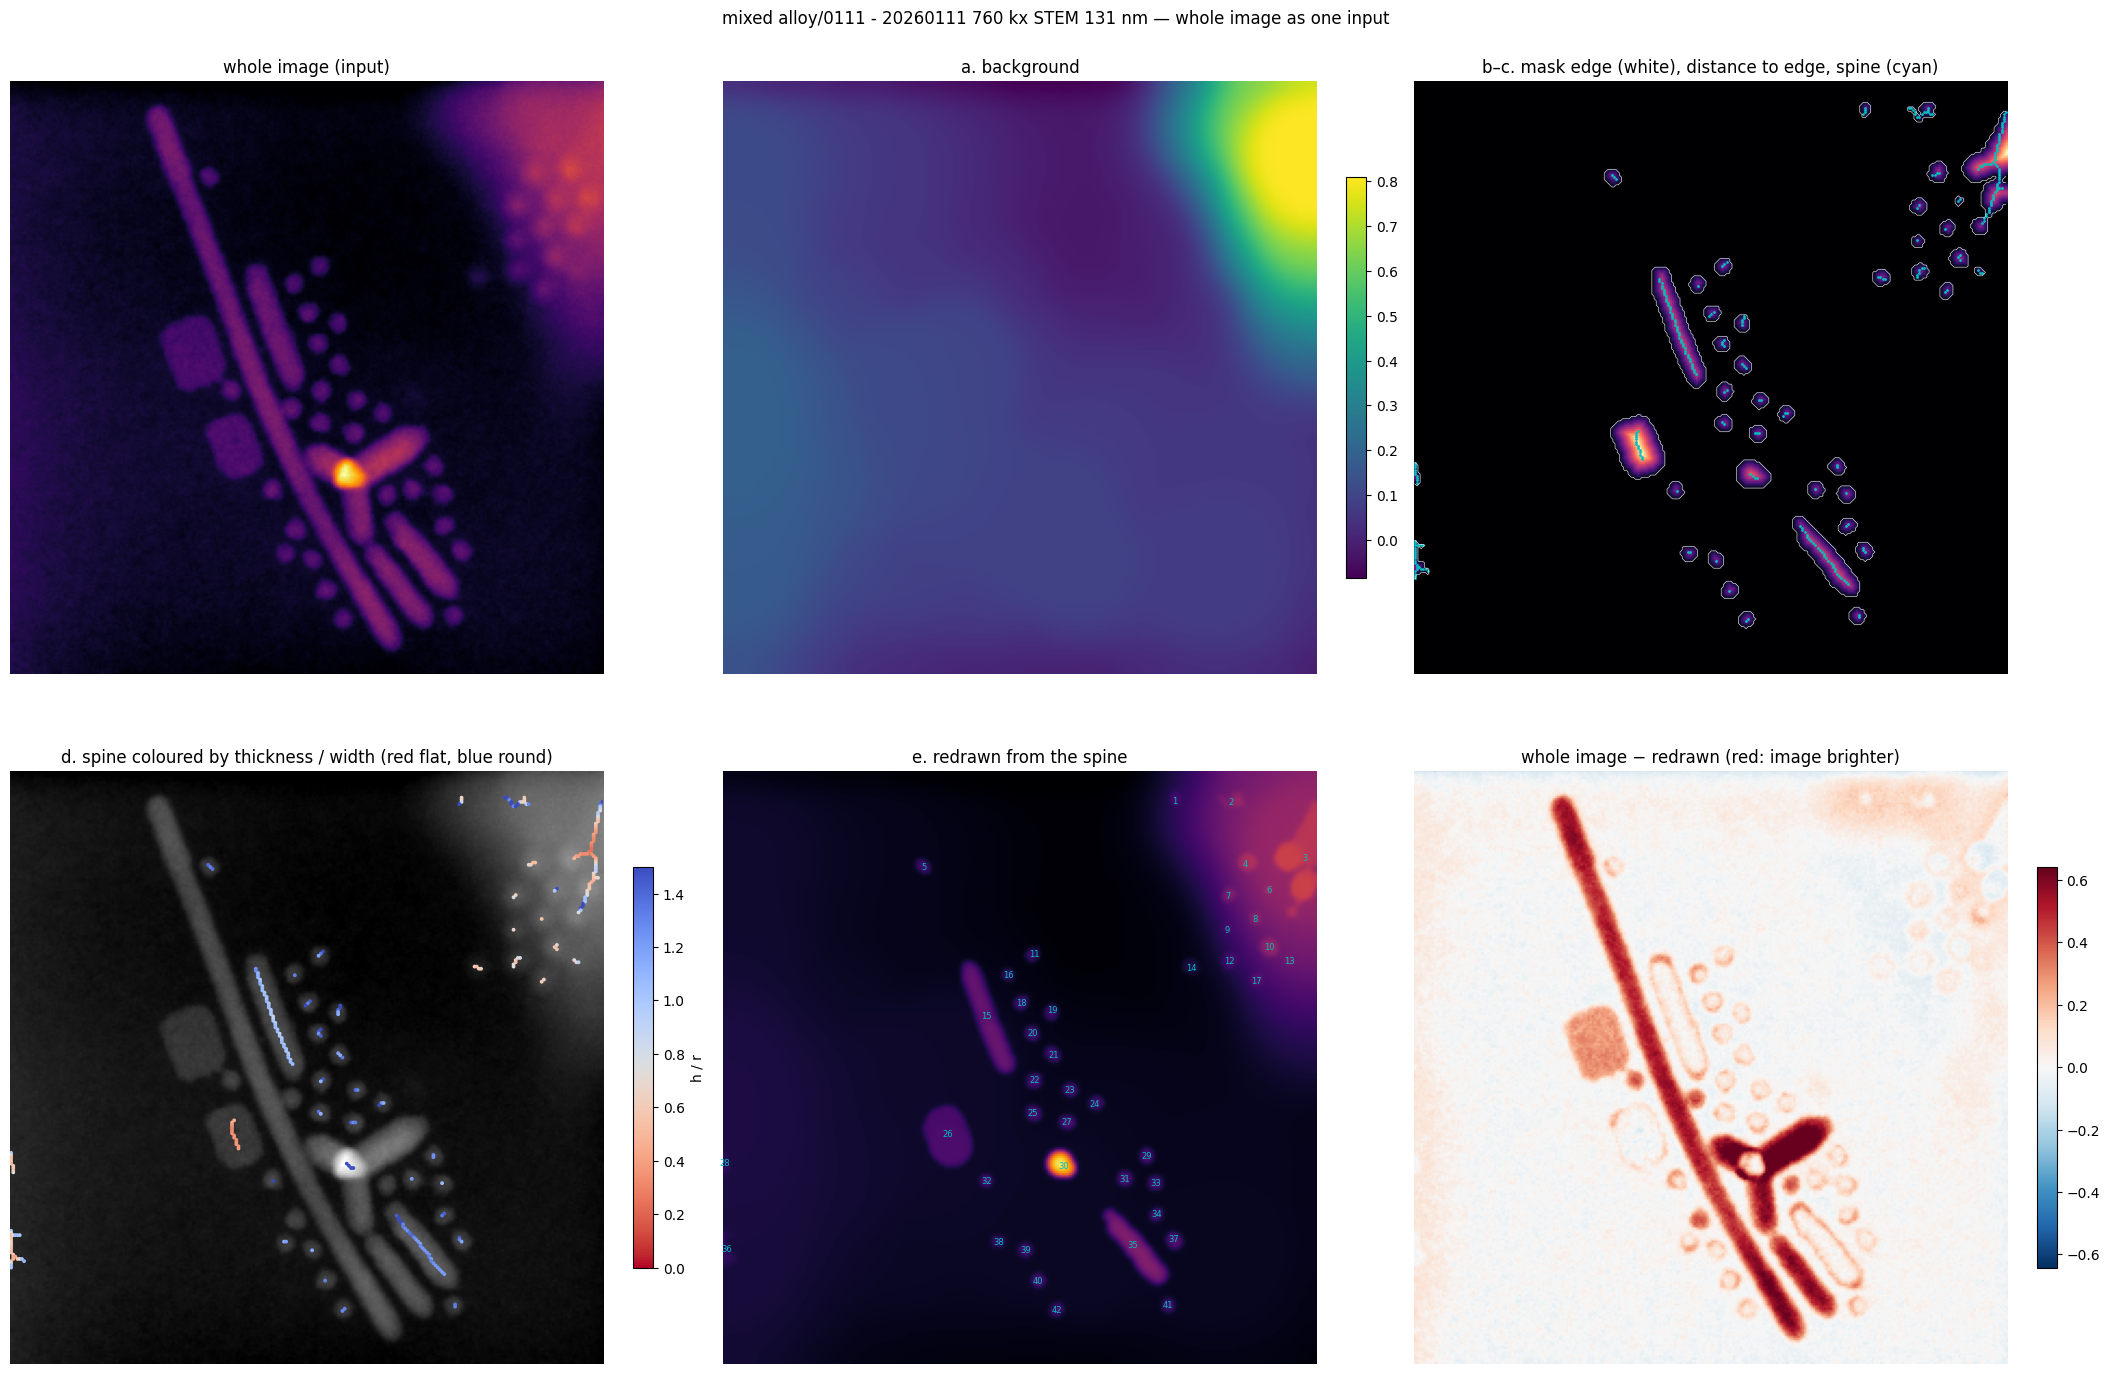

 id  spine_px      x      y  length_nm  width_nm  thickness_nm  h_over_r  touches_edge
 15        45 120.93 113.00      27.42      4.87          5.12      1.02         False
 35        28 188.68 218.50      21.80      5.15          6.56      1.26         False
 26        14 103.07 167.50      15.62      9.24          3.22      0.35         False
 30         4 156.50 182.25       6.98      5.26         19.05      3.58         False
  2        15 233.80  14.00       6.95      1.35          1.74      1.29         False
  4         4 240.50  42.50       4.99      3.48          1.96      0.58         False
 10         3 251.67  81.00       4.89      3.82          2.18      0.57         False
 21         3 152.00 131.00       4.80      3.45          3.89      1.18         False
 19         5 151.40 110.00       4.67      2.70          3.83      1.42         False
 12         6 233.17  87.67       4.53      2.14          1.64      0.73         False
 37         3 207.33 216.00       4.52     

In [22]:
# 8.The whole image as ONE image, every step shown (same method as Cell 6/7)
def show_steps(res, title=''):
    img, bg, mask, xs, ys, hr, drawn, resid = (res[k] for k in ['img', 'bg', 'mask', 'xs', 'ys', 'hr', 'drawn', 'resid'])
    dist = ndi.distance_transform_edt(mask); v = max(img.max(), drawn.max())
    fig, ax = plt.subplots(2, 3, figsize=(21, 14), constrained_layout=True)
    ax[0, 0].imshow(img, cmap='inferno', vmin=-0.05, vmax=v); ax[0, 0].set_title('image')
    im = ax[0, 1].imshow(bg, cmap='viridis'); ax[0, 1].set_title('6a background'); plt.colorbar(im, ax=ax[0, 1], shrink=.6)
    ax[0, 2].imshow(dist, cmap='magma'); ax[0, 2].contour(mask, [.5], colors='w', linewidths=.4); ax[0, 2].scatter(xs, ys, s=1, c='c')
    ax[0, 2].set_title('6b–c mask edge (white), distance to edge, spine (cyan)')
    ax[1, 0].imshow(img, cmap='gray', vmin=-0.05, vmax=v)
    sc = ax[1, 0].scatter(xs, ys, s=3, c=hr, cmap='coolwarm_r', vmin=0, vmax=1.5); plt.colorbar(sc, ax=ax[1, 0], shrink=.6, label='h / r')
    ax[1, 0].set_title('6d spine coloured by thickness / width (red flat, blue round)')
    ax[1, 1].imshow(drawn, cmap='inferno', vmin=-0.05, vmax=v); ax[1, 1].set_title('6e redrawn from the spine')
    for _, p in res['parts'].iterrows(): ax[1, 1].text(p.x, p.y, str(int(p.id)), color='c', fontsize=6, ha='center', va='center')
    l = np.percentile(np.abs(resid), 99.5); im = ax[1, 2].imshow(resid, cmap='RdBu_r', vmin=-l, vmax=l)
    ax[1, 2].set_title('image − redrawn (red: image brighter)'); plt.colorbar(im, ax=ax[1, 2], shrink=.6)
    for a in ax.flat: a.axis('off')
    fig.suptitle(title); plt.show()

WHOLE = spine_analysis(FULL, BG_SIZE=61)                  # BG_SIZE 61: the bright cloud is wide, keep it in the background
P = WHOLE['parts']; Pw = P[~P.touches_edge]
print(f"{CROP_KEY}: {FULL.shape[1]}x{FULL.shape[0]} px = {FULL.shape[1]*NM_PER_PX:.0f} x {FULL.shape[0]*NM_PER_PX:.0f} nm")
print(f"amp {WHOLE['amp']:.4f} | noise {WHOLE['noise']:.4f} | rms inside particles {WHOLE['rms_in']:.4f} (= {WHOLE['rms_in']/WHOLE['noise']:.1f} x noise)")
print(f"{len(P)} particles, {len(Pw)} not touching the edge: {int((Pw.h_over_r < 0.6).sum())} plate-like (h/r < 0.6), "
      f"{int(((Pw.h_over_r >= 0.6) & (Pw.h_over_r <= 1.4)).sum())} round, {int((Pw.h_over_r > 1.4).sum())} too bright for their width (overlaps?)")
show_steps(WHOLE, CROP_KEY)
print(Pw.sort_values('length_nm', ascending=False).round(2).to_string(index=False))

mixed alloy/0111 - 20260111 760 kx STEM 131 nm: 274x274 px = 131 x 131 nm
amp 0.0508 | noise 0.0220 | rms inside particles 0.0862 (= 3.9 x noise)
41 particles, 38 not touching the edge: 7 plate-like (h/r < 0.6), 31 round, 0 too bright for their width (overlaps?)


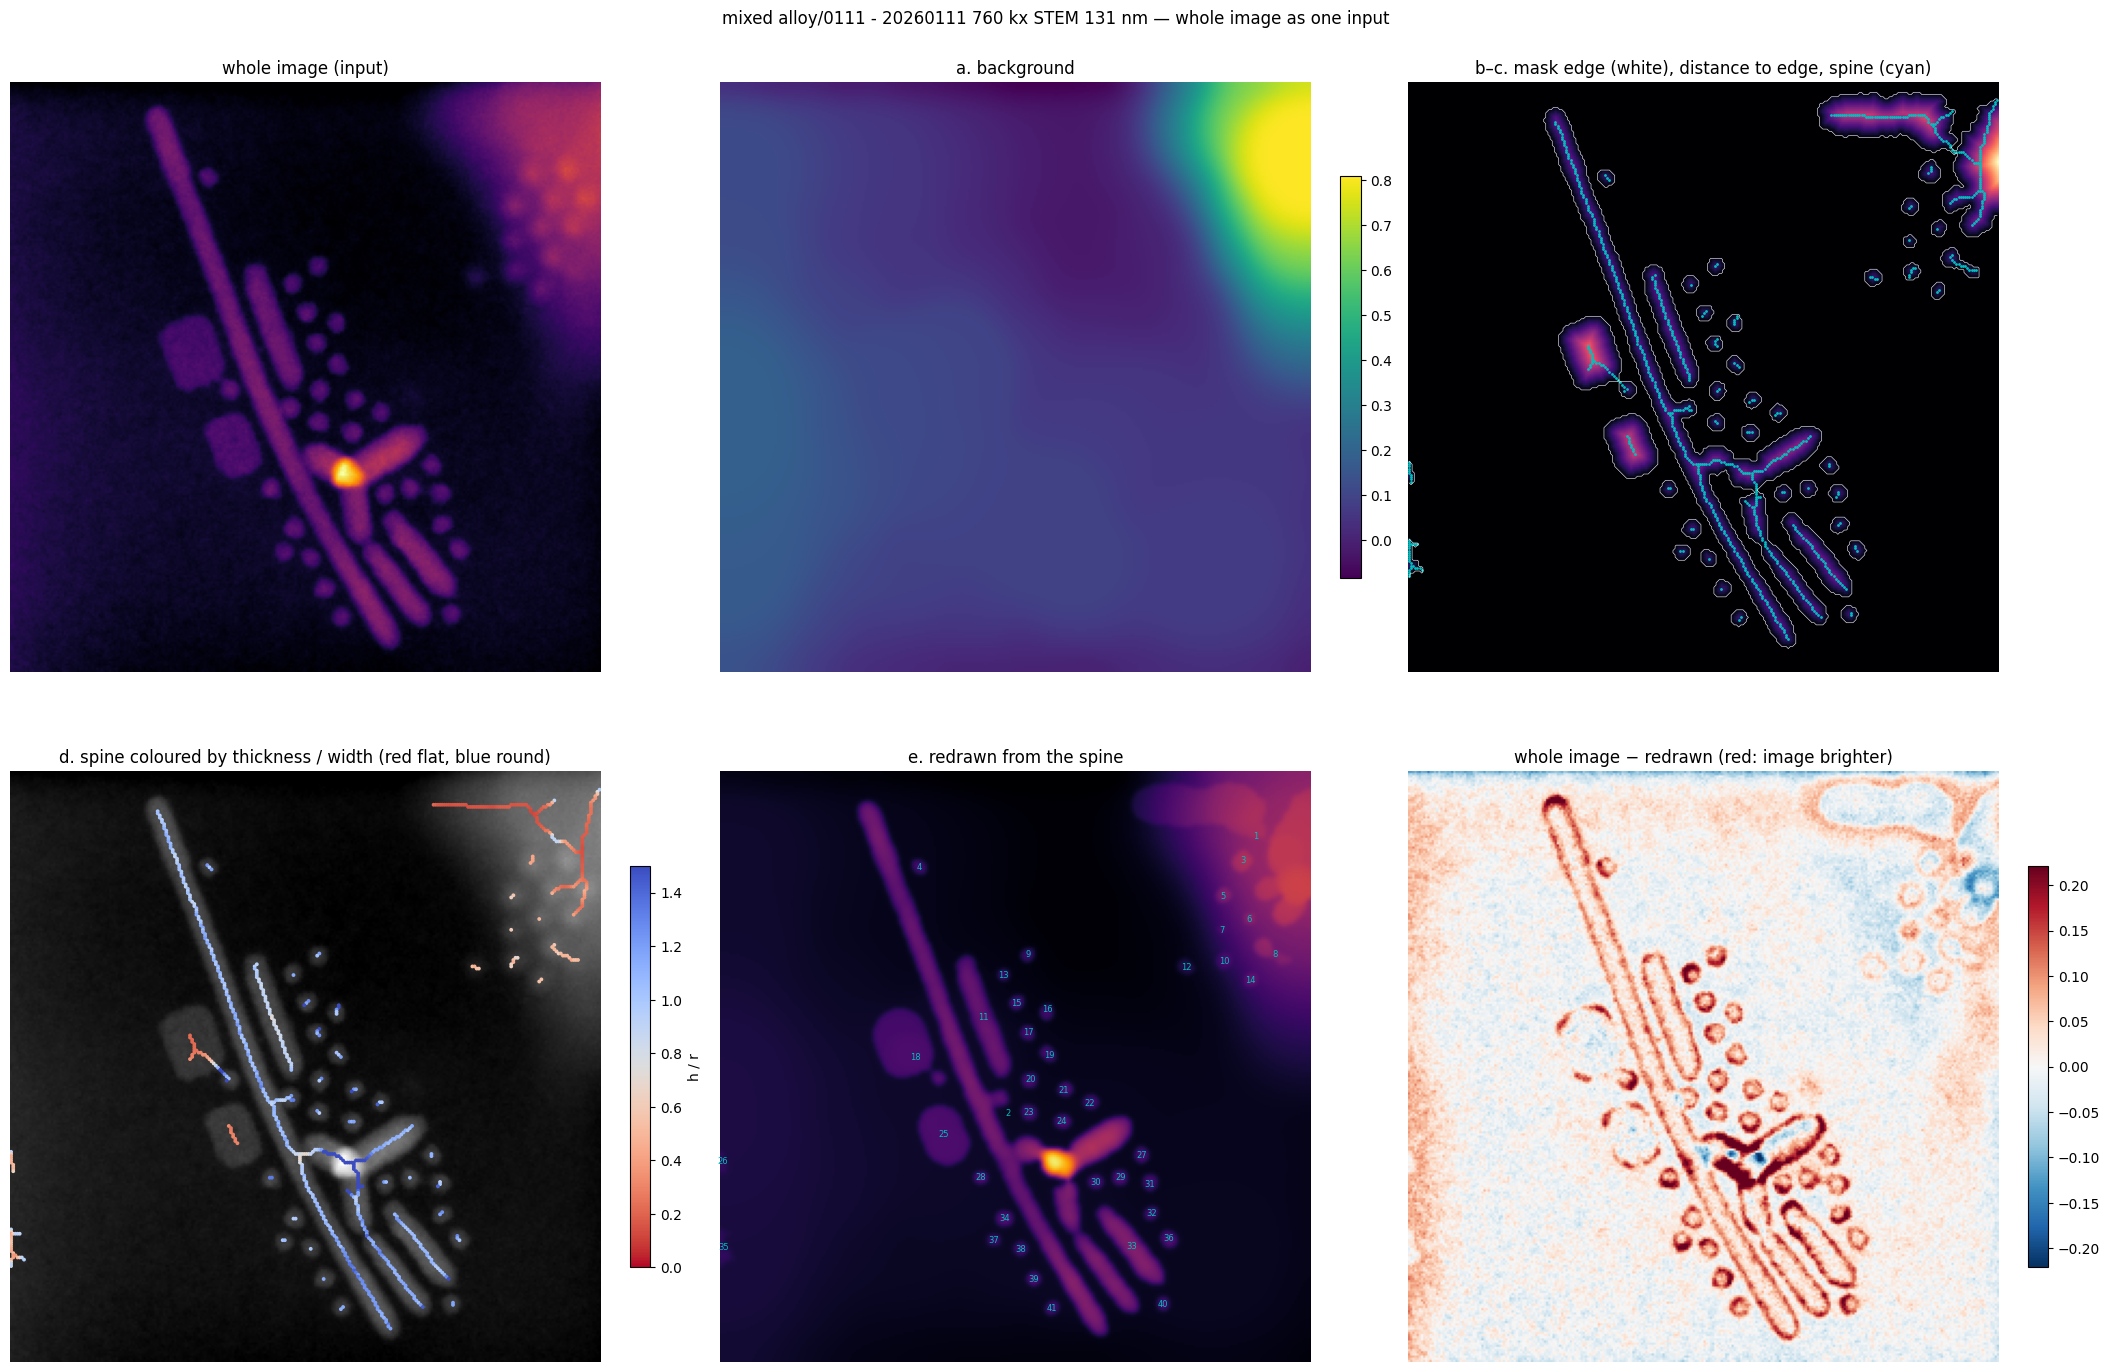

 id  spine_px      x      y  length_nm  width_nm  thickness_nm  h_over_r  touches_edge
  2       380 133.03 158.20     133.69      4.78          5.00      1.10         False
 11        50 121.32 113.50      29.94      5.15          4.48      0.88         False
 33        31 190.23 220.00      24.07      5.41          5.70      1.07         False
 18        29  89.86 132.10      21.77      8.55          2.74      0.34         False
 25         9 102.89 168.00      14.02      9.75          2.86      0.29         False
  8        14 256.64  84.50       8.78      2.14          1.10      0.50         False
  3         4 241.75  40.50       5.26      3.75          1.56      0.42         False
 19         3 152.00 131.00       4.80      3.45          3.41      1.03         False
 16         5 151.40 110.00       4.67      2.70          3.35      1.24         False
 10         6 233.17  87.67       4.53      2.14          1.43      0.64         False
 31         3 198.67 191.00       4.52     

In [24]:
# 9. The WHOLE image as a single input (no crops), every step shown. Independent of Cells 7 and 8.
from scipy import ndimage as ndi
import pandas as pd
from skimage.morphology import remove_small_objects, disk, skeletonize
import warnings; warnings.filterwarnings('ignore', category=FutureWarning)

LOCAL_R_W   = 4      # px; each pixel's edge threshold = half of the brightest value within this radius
BG_SIZE_W   = 61     # px; wider than the widest particle AND wide enough to keep the bright cloud in the background
MIN_AREA_W  = 12     # px; smaller blobs are treated as noise
PLATE_HR_W  = 0.6    # thickness/width below this -> drawn flat-topped (plate), above -> round
PSF_SIGMA_W = 1.0    # px; image blur

def whole_image_analysis(img):
    img = np.asarray(img, np.float32); H, W = img.shape
    # a. background
    bg = ndi.gaussian_filter(ndi.grey_opening(ndi.gaussian_filter(img, 1), footprint=disk(BG_SIZE_W // 2)), 6)
    noise = np.std(img - ndi.gaussian_filter(img, 1)) * 1.4
    rough = ndi.gaussian_filter(img - bg, 1) > 4 * noise
    bg = bg + np.median((img - bg)[~ndi.binary_dilation(rough, iterations=3)])
    smooth = ndi.gaussian_filter(img - bg, 1)
    # b. mask: edge at half of each blob's own peak
    low = remove_small_objects(smooth > 4 * noise, min_size=MIN_AREA_W)
    local_peak = ndi.maximum_filter(smooth, footprint=disk(LOCAL_R_W))
    mask = ndi.binary_fill_holes(remove_small_objects(low & (smooth > 0.5 * local_peak), min_size=MIN_AREA_W))
    # c. spine and half-width
    dist = ndi.distance_transform_edt(mask); spine_px = skeletonize(mask)
    ys, xs = np.nonzero(spine_px); r = np.clip(dist[ys, xs], 0.5, None)
    # d. thickness from brightness (amp: median spine pixel assumed round)
    b = smooth[ys, xs]; amp = np.median(b / (2 * r)); h = b / (2 * amp); hr = h / r
    spine = np.stack([xs, ys, r, h, np.where(hr < PLATE_HR_W, 8.0, 2.0)], 1).astype(np.float32)
    # e. redraw
    drawn = bg + amp * ndi.gaussian_filter(render_from_spine(spine, H, W), PSF_SIGMA_W); resid = img - drawn
    # f. particle list: one particle per connected spine piece
    lab, npart = ndi.label(spine_px, structure=np.ones((3, 3))); rows = []
    for i in range(1, npart + 1):
        sel = lab[ys, xs] == i; yy_, xx_ = ys[sel], xs[sel]
        rows.append(dict(id=i, spine_px=int(sel.sum()), x=xx_.mean(), y=yy_.mean(),
                         length_nm=(np.hypot(np.ptp(xx_), np.ptp(yy_)) + 2 * np.median(r[sel])) * NM_PER_PX,
                         width_nm=2 * np.median(r[sel]) * NM_PER_PX, thickness_nm=2 * np.median(h[sel]) * NM_PER_PX,
                         h_over_r=np.median(hr[sel]),
                         touches_edge=bool((xx_.min() < 2) | (yy_.min() < 2) | (xx_.max() > W - 3) | (yy_.max() > H - 3))))
    return dict(img=img, bg=bg, mask=mask, dist=dist, xs=xs, ys=ys, hr=hr, drawn=drawn, resid=resid, amp=amp, noise=noise,
                parts=pd.DataFrame(rows), rms_in=np.sqrt((resid[mask] ** 2).mean()))

def show_whole_steps(res, title=''):
    img, bg, mask, dist, xs, ys, hr, drawn, resid = (res[k] for k in ['img', 'bg', 'mask', 'dist', 'xs', 'ys', 'hr', 'drawn', 'resid'])
    v = max(img.max(), drawn.max())
    fig, ax = plt.subplots(2, 3, figsize=(21, 14), constrained_layout=True)
    ax[0, 0].imshow(img, cmap='inferno', vmin=-0.05, vmax=v); ax[0, 0].set_title('whole image (input)')
    im = ax[0, 1].imshow(bg, cmap='viridis'); ax[0, 1].set_title('a. background'); plt.colorbar(im, ax=ax[0, 1], shrink=.6)
    ax[0, 2].imshow(dist, cmap='magma'); ax[0, 2].contour(mask, [.5], colors='w', linewidths=.4); ax[0, 2].scatter(xs, ys, s=1, c='c')
    ax[0, 2].set_title('b–c. mask edge (white), distance to edge, spine (cyan)')
    ax[1, 0].imshow(img, cmap='gray', vmin=-0.05, vmax=v)
    sc = ax[1, 0].scatter(xs, ys, s=3, c=hr, cmap='coolwarm_r', vmin=0, vmax=1.5); plt.colorbar(sc, ax=ax[1, 0], shrink=.6, label='h / r')
    ax[1, 0].set_title('d. spine coloured by thickness / width (red flat, blue round)')
    ax[1, 1].imshow(drawn, cmap='inferno', vmin=-0.05, vmax=v); ax[1, 1].set_title('e. redrawn from the spine')
    for _, p in res['parts'].iterrows(): ax[1, 1].text(p.x, p.y, str(int(p.id)), color='c', fontsize=6, ha='center', va='center')
    l = np.percentile(np.abs(resid), 99.5); im = ax[1, 2].imshow(resid, cmap='RdBu_r', vmin=-l, vmax=l)
    ax[1, 2].set_title('whole image − redrawn (red: image brighter)'); plt.colorbar(im, ax=ax[1, 2], shrink=.6)
    for a in ax.flat: a.axis('off')
    fig.suptitle(title); plt.show()

# ---- run: the whole resampled image from Cell 3 is the single input
FULL_IMG = IMAGES[CROP_KEY]['img']
WHOLE_RES = whole_image_analysis(FULL_IMG)
PW = WHOLE_RES['parts']; PW_in = PW[~PW.touches_edge]
print(f"{CROP_KEY}: {FULL_IMG.shape[1]}x{FULL_IMG.shape[0]} px = {FULL_IMG.shape[1]*NM_PER_PX:.0f} x {FULL_IMG.shape[0]*NM_PER_PX:.0f} nm")
print(f"amp {WHOLE_RES['amp']:.4f} | noise {WHOLE_RES['noise']:.4f} | rms inside particles {WHOLE_RES['rms_in']:.4f} (= {WHOLE_RES['rms_in']/WHOLE_RES['noise']:.1f} x noise)")
print(f"{len(PW)} particles, {len(PW_in)} not touching the edge: {int((PW_in.h_over_r < 0.6).sum())} plate-like (h/r < 0.6), "
      f"{int(((PW_in.h_over_r >= 0.6) & (PW_in.h_over_r <= 1.4)).sum())} round, {int((PW_in.h_over_r > 1.4).sum())} too bright for their width (overlaps?)")
show_whole_steps(WHOLE_RES, f'{CROP_KEY} — whole image as one input')
print(PW_in.sort_values('length_nm', ascending=False).round(2).to_string(index=False))

41 particles; not touching the edge: {'dot': 26, 'plate': 7, 'rod': 5}


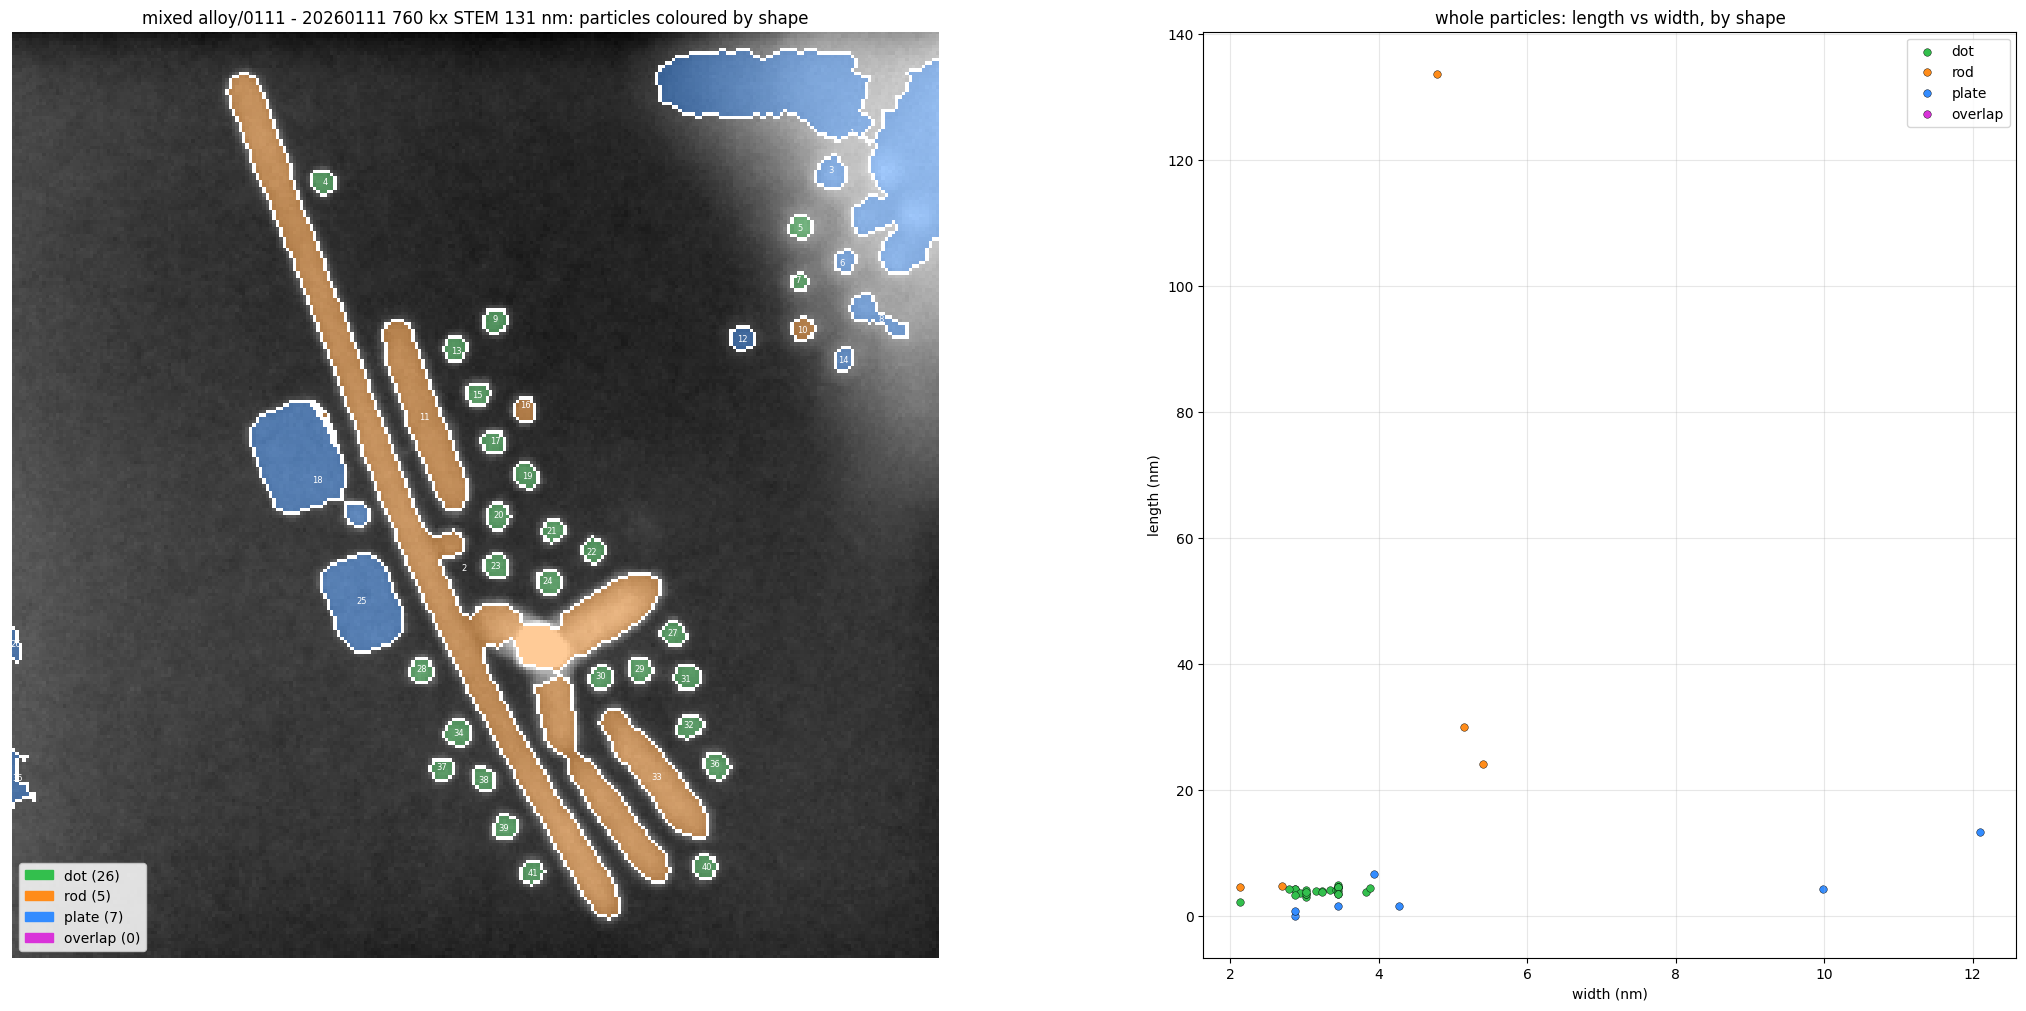

 id shape  length_nm  width_nm  thickness_nm  h_over_r  area_nm2      x      y  touches_edge
 19   dot       4.80      3.45          3.41      1.03     12.11 152.00 131.00         False
 22   dot       4.52      3.45          3.32      0.99     10.97 171.00 153.33         False
 31   dot       4.52      3.45          3.40      0.99     13.02 198.67 191.00         False
 36   dot       4.52      3.45          3.95      1.15     13.02 207.33 216.00         False
 24   dot       4.40      3.45          3.85      1.16     12.11 158.00 162.00         False
 34   dot       4.36      3.88          3.73      0.96     13.94 131.50 207.00         False
 17   dot       4.30      2.79          3.51      1.26     10.51 142.50 120.50         False
  4   dot       4.22      2.87          3.48      1.19     11.42  92.00  44.00         False
 15   dot       4.22      2.87          3.88      1.27     10.74 137.00 107.00         False
 23   dot       4.10      3.42          3.63      1.07     12.11 142.5

In [25]:
# 10. Overlay the particle masks on the image, coloured by shape (uses Cell 9's WHOLE_RES)
from skimage.segmentation import find_boundaries
import matplotlib.patches as mpatches
DOT_ASPECT   = 1.6    # length / width below this = dot, above = rod
PLATE_HR_OV  = 0.6    # h/r below this = plate (flat)
OVERLAP_HR   = 1.4    # h/r above this = brighter than one particle can be: probably overlapping particles
SHAPE_COLOURS = {'dot': (0.20, 0.75, 0.30), 'rod': (1.00, 0.55, 0.10), 'plate': (0.20, 0.55, 1.00), 'overlap': (0.85, 0.20, 0.85)}

def regions_from_spine(res):
    # one region per connected spine piece; every mask pixel goes to the nearest spine piece
    skel = np.zeros(res['mask'].shape, bool); skel[res['ys'], res['xs']] = True
    lab, n = ndi.label(skel, structure=np.ones((3, 3)))
    idx = ndi.distance_transform_edt(lab == 0, return_indices=True)[1]
    return lab[idx[0], idx[1]] * res['mask'], lab

def classify(res, regions, spine_lab):
    dist = res['dist']; hr_map = np.zeros(res['mask'].shape, np.float32); hr_map[res['ys'], res['xs']] = res['hr']
    rows = []
    for i in range(1, regions.max() + 1):
        sp = np.argwhere(spine_lab == i); reg = regions == i
        if len(sp) == 0 or not reg.any(): continue
        rr = np.clip(dist[sp[:, 0], sp[:, 1]], 0.5, None); hrv = float(np.median(hr_map[sp[:, 0], sp[:, 1]]))
        width = 2 * rr.max() if hrv < PLATE_HR_OV else 2 * np.median(rr)
        length = np.hypot(np.ptp(sp[:, 1]), np.ptp(sp[:, 0])) + (0 if hrv < PLATE_HR_OV else width)
        kind = 'overlap' if hrv > OVERLAP_HR else 'plate' if hrv < PLATE_HR_OV else 'rod' if length / width >= DOT_ASPECT else 'dot'
        rows.append(dict(id=i, shape=kind, length_nm=length * NM_PER_PX, width_nm=width * NM_PER_PX,
                         thickness_nm=2 * np.median(hr_map[sp[:, 0], sp[:, 1]] * rr) * NM_PER_PX, h_over_r=hrv,
                         area_nm2=reg.sum() * NM_PER_PX**2, x=sp[:, 1].mean(), y=sp[:, 0].mean(),
                         touches_edge=bool(reg[[0, -1]].any() or reg[:, [0, -1]].any())))
    return pd.DataFrame(rows)

def overlay_shapes(img, regions, table, title='', alpha=0.45, numbers=True):
    rgb = np.dstack([(img - img.min()) / (np.percentile(img, 99.8) - img.min() + 1e-9)] * 3).clip(0, 1)
    paint = np.zeros(img.shape + (3,)); hit = np.zeros(img.shape, bool)
    for _, p in table.iterrows():
        m = regions == p.id; paint[m] = SHAPE_COLOURS[p['shape']]; hit |= m
    out = rgb.copy(); out[hit] = (1 - alpha) * rgb[hit] + alpha * paint[hit]
    out[find_boundaries(regions, mode='inner') & hit] = 1.0                          # white outline around every particle
    fig, ax = plt.subplots(1, 2, figsize=(22, 10), constrained_layout=True, gridspec_kw=dict(width_ratios=[1.6, 1]))
    ax[0].imshow(out)
    if numbers:
        for _, p in table.iterrows(): ax[0].text(p.x, p.y, str(int(p.id)), color='w', fontsize=6, ha='center', va='center')
    counts = table[~table.touches_edge]['shape'].value_counts()
    ax[0].legend(handles=[mpatches.Patch(color=c, label=f"{k} ({counts.get(k, 0)})") for k, c in SHAPE_COLOURS.items()],
                 loc='lower left', fontsize=10, framealpha=.85)
    ax[0].set_title(title); ax[0].axis('off')
    t = table[~table.touches_edge]
    for k, c in SHAPE_COLOURS.items():
        s = t[t['shape'] == k]; ax[1].scatter(s.width_nm, s.length_nm, s=30, color=c, label=k, edgecolor='k', lw=.3)
    ax[1].set_xlabel('width (nm)'); ax[1].set_ylabel('length (nm)'); ax[1].set_title('whole particles: length vs width, by shape')
    ax[1].legend(); ax[1].grid(alpha=.3)
    plt.show()

REGIONS, SPINE_LAB = regions_from_spine(WHOLE_RES)
SHAPES = classify(WHOLE_RES, REGIONS, SPINE_LAB)
print(f"{len(SHAPES)} particles; not touching the edge:", SHAPES[~SHAPES.touches_edge]['shape'].value_counts().to_dict())
overlay_shapes(WHOLE_RES['img'], REGIONS, SHAPES, f'{CROP_KEY}: particles coloured by shape')
print(SHAPES[~SHAPES.touches_edge].sort_values(['shape', 'length_nm'], ascending=[True, False]).round(2).to_string(index=False))

ridge threshold 0.0149 | ridge px per channel: {'0.0°': 43, '22.5°': 56, '45.0°': 176, '67.5°': 601, '90.0°': 79, '112.5°': 45, '135.0°': 38, '157.5°': 76}
pixels lying on ridges in 2+ channels (crossings): 15 | dot px 173 | plate px 999


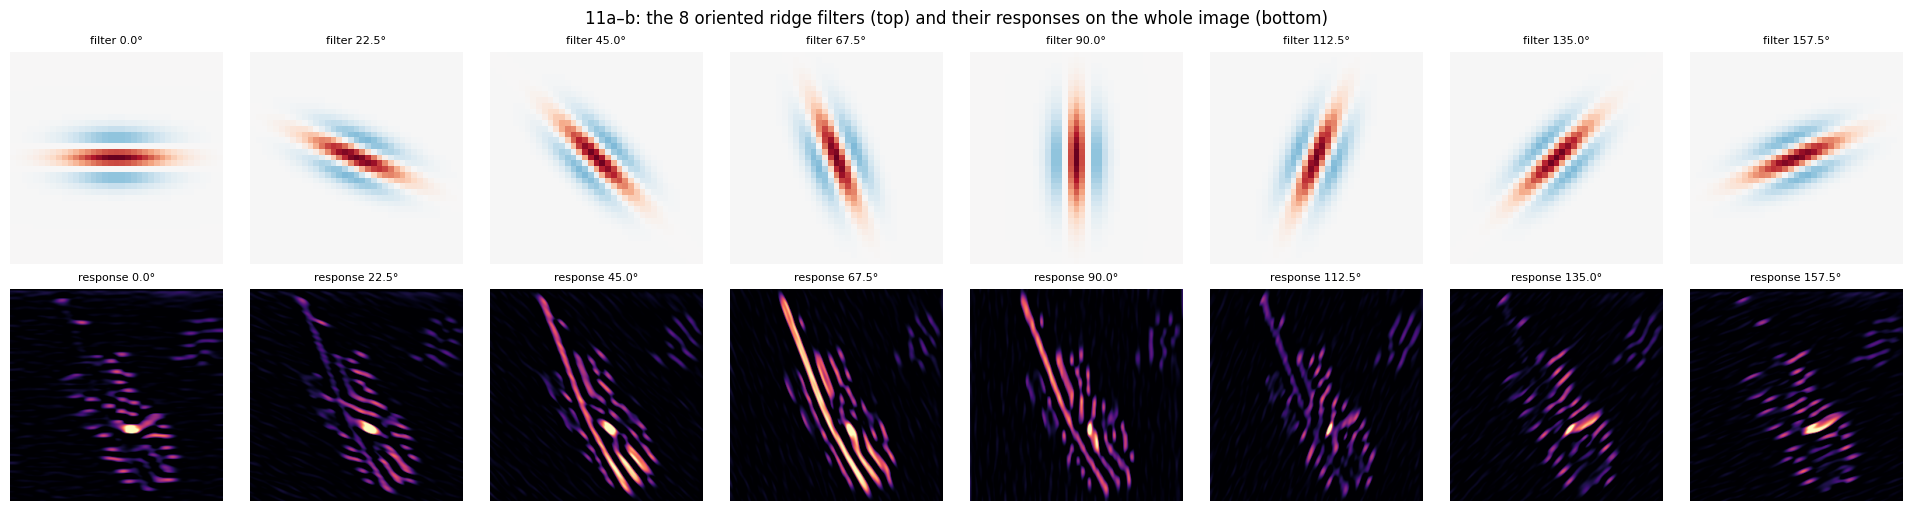

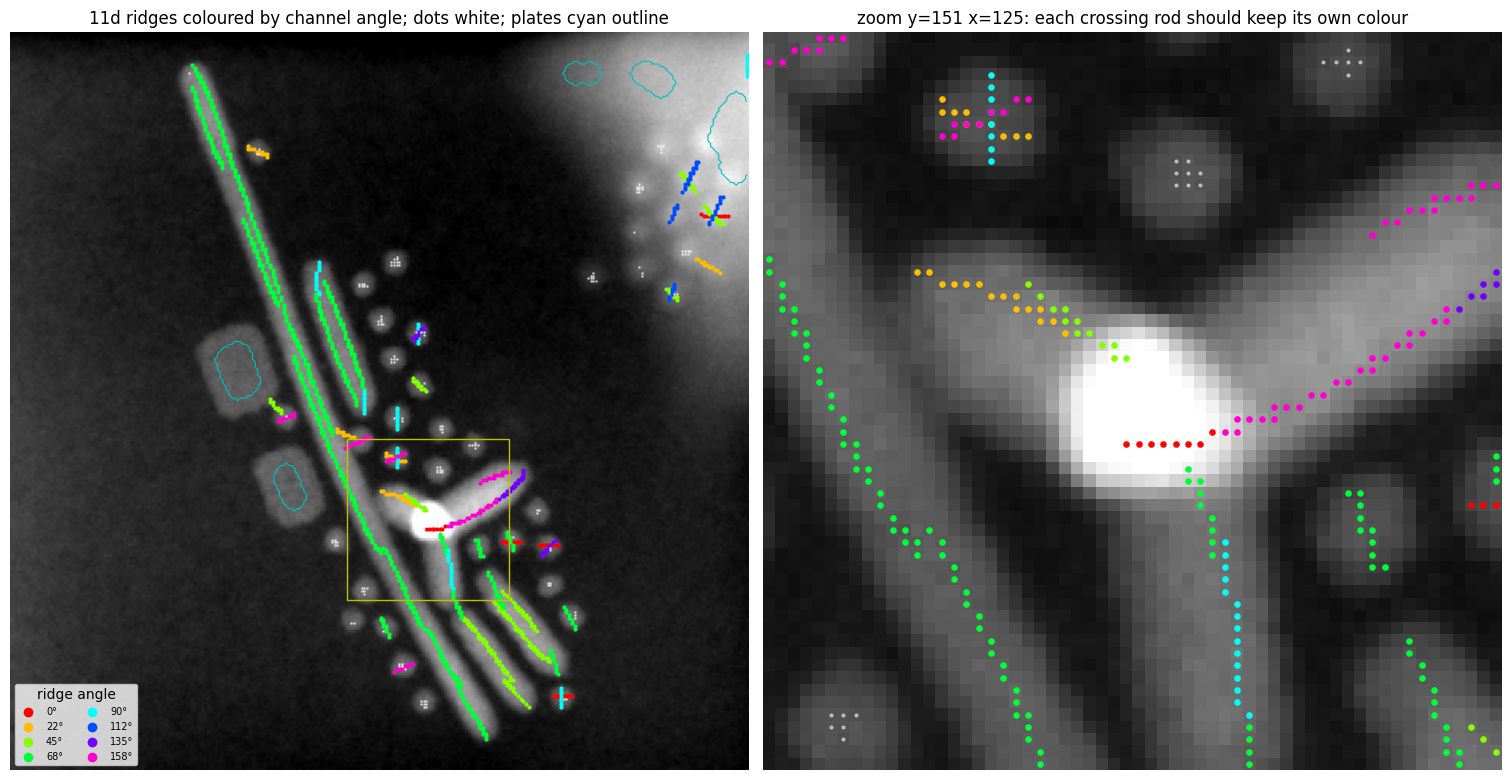

In [26]:
# 11. Spines of round particles from BRIGHTNESS RIDGES, stored in orientation channels (uses Cell 9's WHOLE_RES)
#   touching rods: separate ridges, because brightness dips between them
#   crossing rods: different angles -> different channels, so they never merge
import cv2
from skimage.morphology import disk
N_ANG     = 8       # orientation channels: 0, 22.5, 45 ... 157.5 deg
R_ROD     = 4.0     # px; typical rod half-width (your rods ~8 px wide). Sets the filter size.
SIG_PERP  = 0.5 * R_ROD    # filter width ACROSS a rod (smaller than R_ROD, so the valley between touching rods survives)
SIG_ALONG = 3.0 * SIG_PERP # filter length ALONG a rod (averages noise, ignores short bumps)
THR_K     = 5.0     # ridge must be this many noise-levels above the background response
ANG_RATIO = 0.6     # a channel counts at a pixel only if its response is >= this x the best channel there
BLOB_ANISO = 1.5    # best/worst channel response below this = not elongated (a dot), kept out of the rod channels
PLATE_HR_11 = 0.6   # wide AND flat (thickness/width below this) = plate: ridge filters fire on plate edges, so plates are excluded

img, bg, mask, dist, amp = (WHOLE_RES[k] for k in ['img', 'bg', 'mask', 'dist', 'amp'])
sig = (img - bg).astype(np.float32); H, W = sig.shape
angles = np.arange(N_ANG) * np.pi / N_ANG

# 11a. the filters: minus the 2nd derivative ACROSS the rod of an elongated Gaussian (analytic: only angle and two widths)
def ridge_kernel(theta, sp=SIG_PERP, sa=SIG_ALONG):
    k = int(np.ceil(3 * sa)); y, x = np.mgrid[-k:k + 1, -k:k + 1].astype(np.float32)
    u = x * np.cos(theta) + y * np.sin(theta); v = -x * np.sin(theta) + y * np.cos(theta)    # u along the rod, v across
    g = np.exp(-u**2 / (2 * sa**2) - v**2 / (2 * sp**2))
    kern = -(v**2 / sp**4 - 1 / sp**2) * g                    # positive on the axis, negative on both sides
    kern -= kern.mean(); return (kern / np.abs(kern).sum()).astype(np.float32)
KERNELS = [ridge_kernel(t) for t in angles]

# 11b. one response map per angle
R = np.stack([cv2.filter2D(sig, -1, k, borderType=cv2.BORDER_REFLECT) for k in KERNELS]).clip(0, None)
Rmax, Rmin = R.max(0), R.min(0)
bgv = Rmax[~ndi.binary_dilation(mask, iterations=3)]
thr = np.median(bgv) + THR_K * 1.4826 * np.median(np.abs(bgv - np.median(bgv)))

# 11c. which pixels are NOT rod material: dots (round, no preferred angle) and plates (wide and flat)
blob = (Rmax > thr) & (Rmax / (Rmin + 1e-9) < BLOB_ANISO)
flatness = sig / (2 * amp * np.maximum(dist, 0.5))           # thickness / width at each pixel
# a plate = a SOLID area that is wide, flat AND has no ridge inside, wider than a rod. (Two touching rods are wide too,
#           but they have strong ridges; the thin ridge-free valley between them is removed by the opening.)
strong_ridge = ndi.gaussian_filter(Rmax, 1) > 2 * thr                  # clearly on a rod axis (noise on a plate stays below)
plate_core = (dist > 1.5 * R_ROD) & (flatness < PLATE_HR_11) & ~strong_ridge
plate_core = ndi.binary_opening(plate_core, structure=disk(int(R_ROD)))
plate_zone = ndi.binary_dilation(plate_core, iterations=int(R_ROD) + 4) & mask

# 11d. ridges per channel: strongest across the rod (non-max suppression), a peak over angle, and strong enough
yy, xx = np.mgrid[:H, :W].astype(np.float32)
RIDGE = np.zeros((N_ANG, H, W), bool)
for a, t in enumerate(angles):
    nx, ny = -np.sin(t), np.cos(t)                            # unit step across the rod
    plus = ndi.map_coordinates(R[a], [yy + ny, xx + nx], order=1, mode='nearest')
    minus = ndi.map_coordinates(R[a], [yy - ny, xx - nx], order=1, mode='nearest')
    ang_peak = (R[a] >= R[(a - 1) % N_ANG]) & (R[a] >= R[(a + 1) % N_ANG])
    RIDGE[a] = (R[a] >= plus) & (R[a] >= minus) & ang_peak & (R[a] > thr) & (R[a] >= ANG_RATIO * Rmax) & mask & ~blob & ~plate_zone
    lab, n = ndi.label(RIDGE[a], structure=np.ones((3, 3)))          # remove specks: a ridge must be at least ~R_ROD long
    sizes = ndi.sum(np.ones_like(lab), lab, range(1, n + 1))
    RIDGE[a] &= np.isin(lab, np.where(sizes >= 2 * R_ROD)[0] + 1)   # shorter pieces are dots or noise
n_channels_here = RIDGE.sum(0)
print(f"ridge threshold {thr:.4f} | ridge px per channel:", {f"{np.degrees(t):.1f}°": int(RIDGE[a].sum()) for a, t in enumerate(angles)})
print(f"pixels lying on ridges in 2+ channels (crossings): {int((n_channels_here >= 2).sum())} | dot px {int(blob.sum())} | plate px {int(plate_core.sum())}")

# ---- pictures
fig, ax = plt.subplots(2, N_ANG, figsize=(2.4 * N_ANG, 5), constrained_layout=True)
for a, t in enumerate(angles):
    l = np.abs(KERNELS[a]).max(); ax[0, a].imshow(KERNELS[a], cmap='RdBu_r', vmin=-l, vmax=l); ax[0, a].set_title(f'filter {np.degrees(t):.1f}°', fontsize=8)
    ax[1, a].imshow(R[a], cmap='magma', vmin=0, vmax=np.percentile(Rmax, 99.5)); ax[1, a].set_title(f'response {np.degrees(t):.1f}°', fontsize=8)
for x_ in ax.flat: x_.axis('off')
fig.suptitle('11a–b: the 8 oriented ridge filters (top) and their responses on the whole image (bottom)'); plt.show()

ang_cmap = plt.get_cmap('hsv')
def draw_ridges(a_, ys0=0, xs0=0, sz=None):
    for a, t in enumerate(angles):
        py, px = np.nonzero(RIDGE[a]); sel = np.ones(len(px), bool)
        if sz: sel = (py >= ys0) & (py < ys0 + sz) & (px >= xs0) & (px < xs0 + sz)
        a_.scatter(px[sel] - xs0, py[sel] - ys0, s=4 if sz is None else 14, color=ang_cmap(a / N_ANG), label=f'{np.degrees(t):.0f}°')
    py, px = np.nonzero(blob); sel = np.ones(len(px), bool)
    if sz: sel = (py >= ys0) & (py < ys0 + sz) & (px >= xs0) & (px < xs0 + sz)
    a_.scatter(px[sel] - xs0, py[sel] - ys0, s=1 if sz is None else 4, c='w', alpha=.5)

cy, cx = np.unravel_index(np.argmax(ndi.gaussian_filter(sig, 2)), sig.shape)       # brightest spot = the crossing
ZOOMS = [(max(0, cy - 30), max(0, cx - 30), 60)]          # (top, left, size); add your own, e.g. the touching rods
fig, ax = plt.subplots(1, 1 + len(ZOOMS), figsize=(9 + 6 * len(ZOOMS), 8.5), constrained_layout=True, squeeze=False); ax = ax[0]
ax[0].imshow(img, cmap='gray', vmin=-0.05, vmax=np.percentile(img, 99.8)); draw_ridges(ax[0])
ax[0].contour(plate_core, [.5], colors='c', linewidths=.8)
for (zy, zx, zs) in ZOOMS: ax[0].add_patch(plt.Rectangle((zx - .5, zy - .5), zs, zs, fill=False, ec='y'))
ax[0].legend(fontsize=7, markerscale=3, loc='lower left', ncol=2, title='ridge angle'); ax[0].set_title('11d ridges coloured by channel angle; dots white; plates cyan outline')
for j, (zy, zx, zs) in enumerate(ZOOMS, 1):
    ax[j].imshow(img[zy:zy + zs, zx:zx + zs], cmap='gray', vmin=-0.05, vmax=np.percentile(img, 99.9)); draw_ridges(ax[j], zy, zx, zs)
    ax[j].set_title(f'zoom y={zy} x={zx}: each crossing rod should keep its own colour')
for x_ in ax: x_.axis('off')
plt.show()

12c: 188 ridge pieces -> 47 rods
51 particles (50 not touching the edge): {'rod': 47, 'plate': 3} | unassigned mask pixels: 85 (0.8% of the mask)
pixels covered by 2+ particles (crossings): 1714


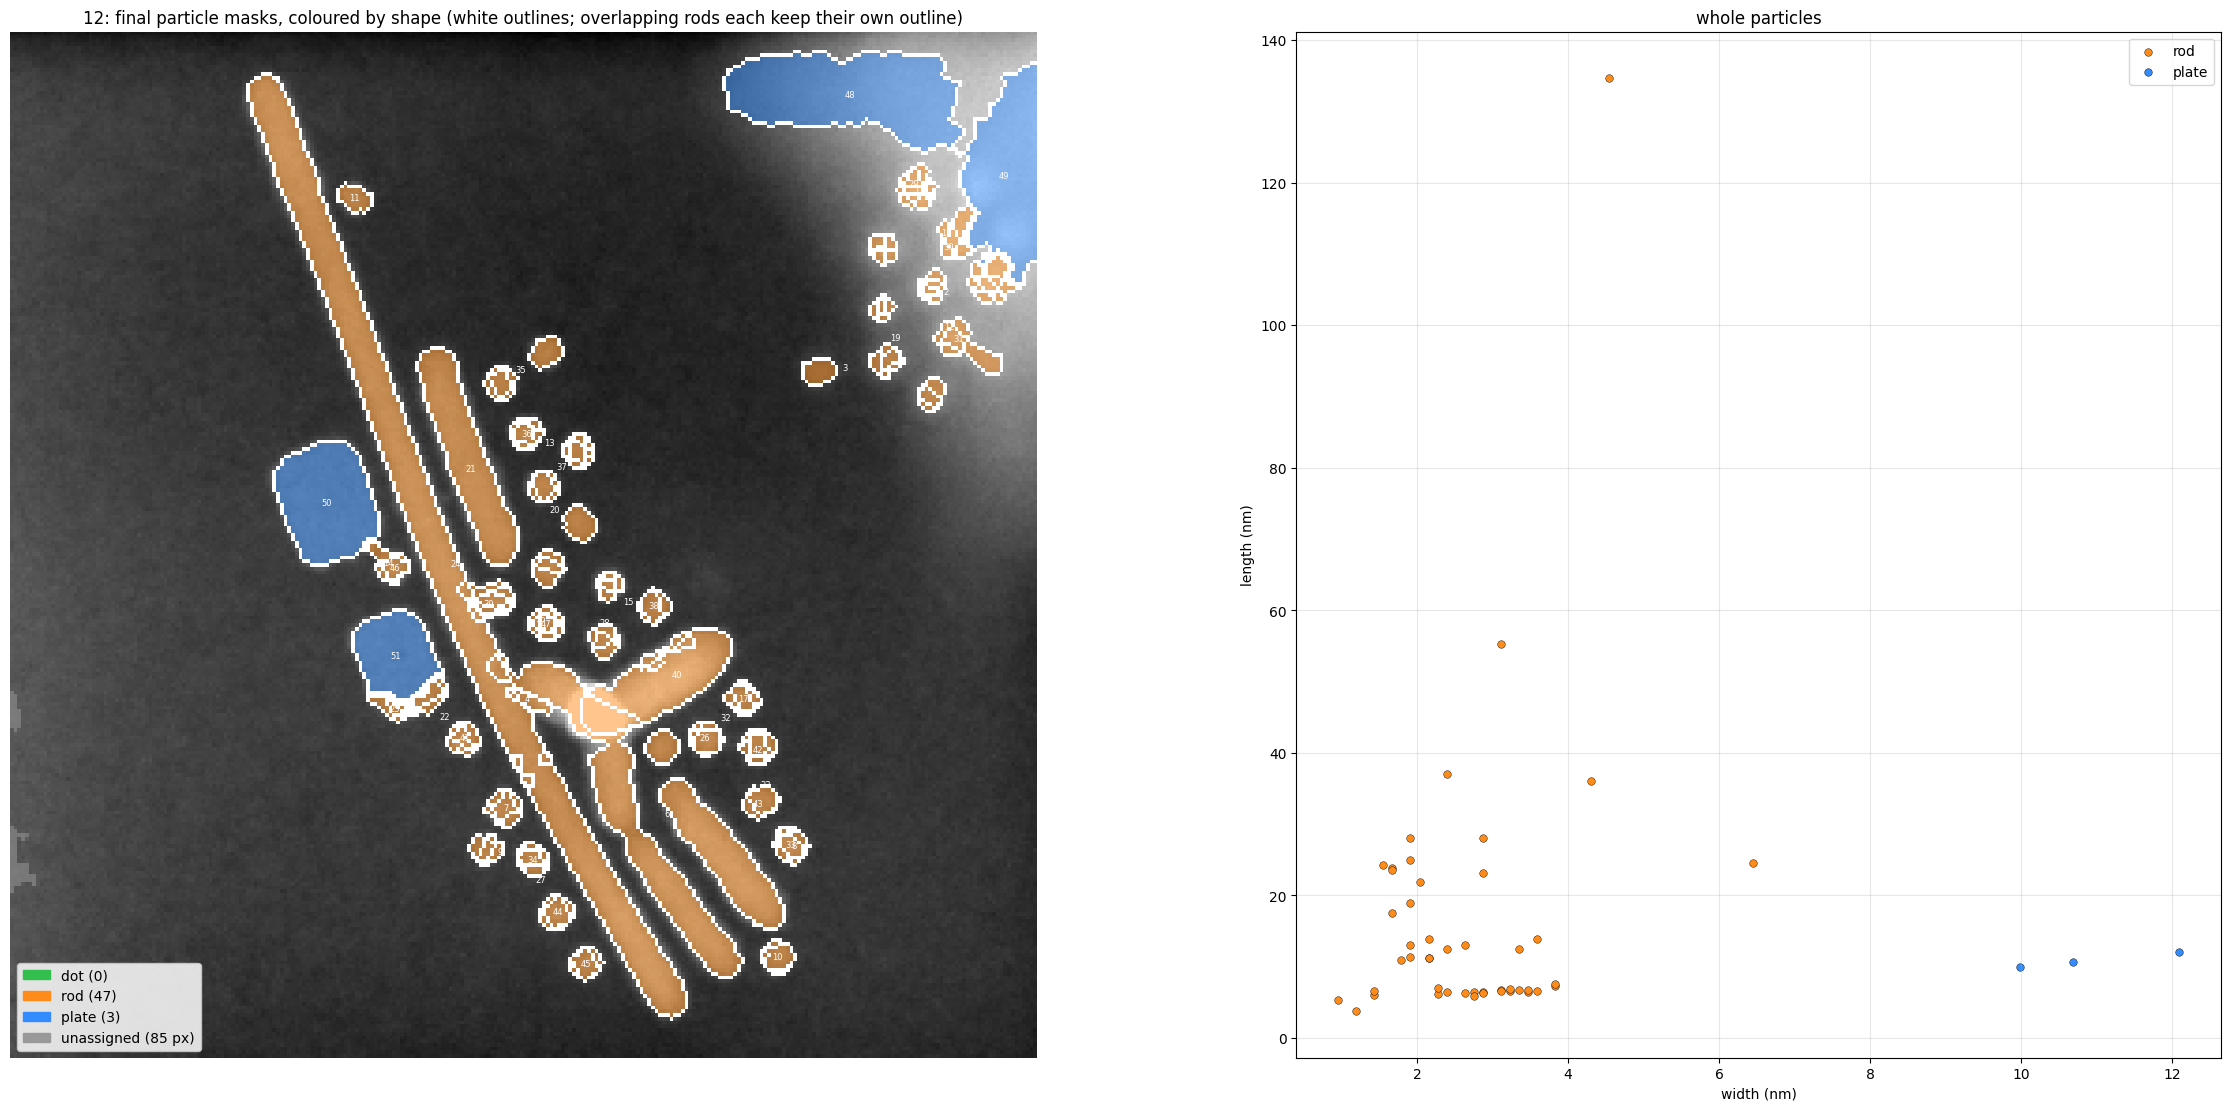

 id shape  length_nm  width_nm  thickness_nm  h_over_r  area_nm2      x      y  touches_edge
 50 plate      12.09     12.09          2.70      0.22    167.02  84.09 125.21         False
 48 plate      10.69     10.69          1.34      0.13    288.35 223.75  16.38         False
 51 plate       9.98      9.98          2.91      0.29    100.76 102.40 166.17         False
 24   rod     134.66      4.54          4.95      1.09    637.93 118.50 141.69         False
  6   rod      55.27      3.11          5.37      1.73    423.84 174.95 208.41         False
 20   rod      36.98      2.39          3.22      1.35     89.34 144.82 127.27         False
 21   rod      36.12      4.30          4.38      1.02    171.59 122.41 116.35         False
 16   rod      28.10      1.91          3.34      1.75     40.90 141.23 156.43         False
 27   rod      28.09      2.87          3.31      1.16     53.92 141.14 225.89         False
 23   rod      25.04      1.91          3.24      1.69     46.15 201.3

In [27]:
# 12. Final particle masks: rods from ridges (multi-width, joined across channels and crossings), dots, plates.
#           Every particle gets its own mask; crossing rods' masks are allowed to overlap.  Uses Cell 9's WHOLE_RES only.
import cv2
from skimage.morphology import disk
from skimage.segmentation import find_boundaries
import matplotlib.patches as mpatches
N_ANG12   = 8                    # orientation channels
SIGMAS    = [1.5, 2.5, 3.5]      # px; filter widths across a rod. The best one per pixel is kept (fixes double ridges on flat rods)
ALONG     = 3.0                  # filter length along a rod = ALONG x width
THR12_K   = 5.0                  # ridge must be this many noise-levels above background
ANG12_RATIO = 0.6
BLOB12_ANISO = 1.5               # best/worst angle response below this = a dot
PLATE12_HR = 0.6                 # flat: thickness / width below this
JOIN_GAP  = 14                   # px; ridge pieces this close (end to end) and in line are the same rod (bridges crossings)
JOIN_DEG  = 25                   # ... "in line" = within this angle
JOIN_OFFSET = 3.0                # ... and the lateral offset between their lines below this (px)
MIN_ROD_PX = 8                   # rods with fewer ridge pixels are dropped (noise)
SHAPE12_COLOURS = {'dot': (0.20, 0.75, 0.30), 'rod': (1.00, 0.55, 0.10), 'plate': (0.20, 0.55, 1.00), 'unassigned': (0.6, 0.6, 0.6)}

img, bg, mask, dist, amp = (WHOLE_RES[k] for k in ['img', 'bg', 'mask', 'dist', 'amp'])
sig = (img - bg).astype(np.float32); H, W = sig.shape
angs = np.arange(N_ANG12) * np.pi / N_ANG12
yy, xx = np.mgrid[:H, :W].astype(np.float32)

# ---- 12a. multi-width ridge responses: for each angle, the best over widths (scale-normalised so widths compare fairly)
def kern(theta, sp):
    sa = ALONG * sp; k = int(np.ceil(3 * sa)); y, x = np.mgrid[-k:k + 1, -k:k + 1].astype(np.float32)
    u = x * np.cos(theta) + y * np.sin(theta); v = -x * np.sin(theta) + y * np.cos(theta)
    g = np.exp(-u**2 / (2 * sa**2) - v**2 / (2 * sp**2)); g /= g.sum()
    return (-(v**2 / sp**4 - 1 / sp**2) * g * sp**2).astype(np.float32)         # x sp^2: scale-normalised
Rs = np.stack([np.stack([cv2.filter2D(sig, -1, kern(t, s), borderType=cv2.BORDER_REFLECT) for t in angs]) for s in SIGMAS])
R12 = Rs.max(0).clip(0, None); BEST_SIG = np.array(SIGMAS)[Rs.argmax(0)]          # (angle, H, W)
Rmax12, Rmin12 = R12.max(0), R12.min(0)
bgv = Rmax12[~ndi.binary_dilation(mask, iterations=3)]
thr12 = np.median(bgv) + THR12_K * 1.4826 * np.median(np.abs(bgv - np.median(bgv)))

# ---- 12b. dots, plates, then ridge pixels per channel
blob12 = (Rmax12 > thr12) & (Rmax12 / (Rmin12 + 1e-9) < BLOB12_ANISO) & mask
R_TYP = float(np.median(dist[mask & (dist > 0)])) if mask.any() else 3.0
flat12 = sig / (2 * amp * np.maximum(dist, 0.5))
# "ridge-like" is RELATIVE: on a rod axis the ridge response is a large fraction of the brightness, on a flat plate a small one
ratio12 = ndi.gaussian_filter(Rmax12, 1) / np.maximum(ndi.gaussian_filter(sig, 1), 1e-6)
rod_ratio = np.percentile(ratio12[mask & (Rmax12 > thr12)], 90) if (mask & (Rmax12 > thr12)).any() else 1.0
strong = ratio12 > 0.4 * rod_ratio
plate_core12 = ndi.binary_opening((dist > 1.5 * max(R_TYP, 3)) & (flat12 < PLATE12_HR) & ~strong, structure=disk(int(max(R_TYP, 3))))
plate_zone12 = ndi.binary_dilation(plate_core12, iterations=int(max(R_TYP, 3)) + 4) & mask
RID = np.zeros((N_ANG12, H, W), bool)
for a, t in enumerate(angs):
    nx, ny = -np.sin(t), np.cos(t)
    pl = ndi.map_coordinates(R12[a], [yy + ny, xx + nx], order=1, mode='nearest'); mi = ndi.map_coordinates(R12[a], [yy - ny, xx - nx], order=1, mode='nearest')
    peak_a = (R12[a] >= R12[(a - 1) % N_ANG12]) & (R12[a] >= R12[(a + 1) % N_ANG12])
    RID[a] = (R12[a] >= pl) & (R12[a] >= mi) & peak_a & (R12[a] > thr12) & (R12[a] >= ANG12_RATIO * Rmax12) & mask & ~blob12 & ~plate_zone12

# ---- 12c. ridge pieces (per channel) -> rods: join pieces in the same/neighbouring channel that touch, or that continue in a line
pieces = []
for a in range(N_ANG12):
    lab, n = ndi.label(RID[a], structure=np.ones((3, 3)))
    for i in range(1, n + 1):
        p = np.argwhere(lab == i).astype(np.float32)                  # (y, x)
        if len(p) < 3: continue
        c = p.mean(0); _, _, vt = np.linalg.svd(p - c, full_matrices=False); d = vt[0] if len(p) > 2 else np.array([np.sin(angs[a]), np.cos(angs[a])])
        proj = (p - c) @ d
        pieces.append(dict(a=a, pix=p, c=c, d=d, e0=c + proj.min() * d, e1=c + proj.max() * d))
par = list(range(len(pieces)))
def fnd(i):
    while par[i] != i: par[i] = par[par[i]]; i = par[i]
    return i
pix_owner = np.full((H, W), -1, np.int32)
for i, p in enumerate(pieces): pix_owner[tuple(p['pix'].astype(int).T)] = i
for i, p in enumerate(pieces):                                       # touching pieces in neighbouring channels (a curved rod)
    nb = ndi.binary_dilation(pix_owner == i, np.ones((3, 3)), iterations=2)
    for j in set(np.unique(pix_owner[nb])) - {-1, i}:
        if min(abs(p['a'] - pieces[j]['a']), N_ANG12 - abs(p['a'] - pieces[j]['a'])) <= 1: par[fnd(i)] = fnd(j)
def ang_between(u, v): return np.degrees(np.arccos(np.clip(abs(np.dot(u, v)), -1, 1)))
for i, p in enumerate(pieces):                                       # pieces continuing in a line across a gap or a crossing
    for j in range(i + 1, len(pieces)):
        q = pieces[j]
        if ang_between(p['d'], q['d']) > JOIN_DEG: continue
        ends = [(np.hypot(*(e - f)), e, f) for e in (p['e0'], p['e1']) for f in (q['e0'], q['e1'])]
        gap, e, f = min(ends, key=lambda z: z[0])
        if gap > JOIN_GAP: continue
        dm = p['d'] + np.sign(np.dot(p['d'], q['d'])) * q['d']; dm /= np.hypot(*dm)
        dv = q['c'] - p['c']; off = abs(dm[0] * dv[1] - dm[1] * dv[0])  # lateral offset between the two lines
        if off < JOIN_OFFSET: par[fnd(i)] = fnd(j)
rods = {}
for i in range(len(pieces)): rods.setdefault(fnd(i), []).append(i)
rods = [np.concatenate([pieces[i]['pix'] for i in g]) for g in rods.values()]
rods = [r for r in rods if len(r) >= MIN_ROD_PX]
print(f"12c: {len(pieces)} ridge pieces -> {len(rods)} rods")

# ---- 12d. each rod's width (half-max of the brightness profile across it) and thickness, then its own mask
crossing_px = RID.sum(0) >= 2
def half_width(py, px, theta):
    nx, ny = -np.sin(theta), np.cos(theta); t = np.arange(-15, 15.5, 0.5)
    prof = ndi.map_coordinates(sig, [py + t * ny, px + t * nx], order=1, mode='nearest'); c = len(t) // 2; pk = prof[c]
    if pk <= 0: return np.nan
    out = []
    for side in (1, -1):
        k = c
        while 0 < k < len(t) - 1 and prof[k + side] > 0.5 * pk and prof[k + side] <= prof[k] + 0.02 * pk: k += side
        out.append(abs(t[k]) + 0.25)
    return np.mean(out)
instances = []
for rp in rods:
    c = rp.mean(0); _, _, vt = np.linalg.svd(rp - c, full_matrices=False); d = vt[0]; theta = np.arctan2(d[0], d[1])
    smp = rp[np.linspace(0, len(rp) - 1, min(len(rp), 40)).astype(int)]
    hw = np.nanmedian([half_width(py, px, theta) for py, px in smp])
    clean = ~crossing_px[tuple(rp.astype(int).T)]
    pkb = sig[tuple(rp.astype(int).T)][clean] if clean.any() else sig[tuple(rp.astype(int).T)]
    ridge_img = np.zeros((H, W), bool); ridge_img[tuple(rp.astype(int).T)] = True
    m = (ndi.distance_transform_edt(~ridge_img) <= hw) & ndi.binary_dilation(mask, iterations=1)
    proj = (rp - c) @ d
    instances.append(dict(shape='rod', mask=m, length=float(np.ptp(proj) + 2 * hw), width=float(2 * hw),
                          thick=float(np.median(pkb) / amp), y=c[0], x=c[1]))

# ---- 12e. dots: one disk per blob, radius from the brightness profile (half-max, averaged over 8 directions)
lab_b, nbl = ndi.label(blob12)
taken = np.zeros((H, W), bool)
for ins in instances: taken |= ins['mask']
for i in range(1, nbl + 1):
    cy_, cx_ = np.array(ndi.maximum_position(ndi.gaussian_filter(sig, 1) * (lab_b == i))).astype(np.float32)
    if taken[int(cy_), int(cx_)] or plate_zone12[int(cy_), int(cx_)]: continue   # already inside a rod, or a plate
    rad = np.nanmedian([half_width(cy_, cx_, t) for t in angs])
    if not rad >= 1.5: continue                                      # too small to be a particle: noise
    m = (np.hypot(xx - cx_, yy - cy_) <= rad) & ndi.binary_dilation(mask, iterations=1)
    instances.append(dict(shape='dot', mask=m, length=float(2 * rad), width=float(2 * rad),
                          thick=float(sig[int(cy_), int(cx_)] / amp), y=cy_, x=cx_))

# ---- 12f. plates: each plate core grown out over the mask pixels no rod or dot claims
taken = np.zeros((H, W), bool)
for ins in instances: taken |= ins['mask']
lab_p, npl = ndi.label(plate_core12)
free = mask & ~taken
grown = np.zeros((H, W), np.int32); grown[plate_core12] = lab_p[plate_core12]
for _ in range(int(3 * max(R_TYP, 3))):                              # grow step by step, only into free mask pixels
    g2 = ndi.grey_dilation(grown, size=3) * (free & (grown == 0)); grown = np.where(grown > 0, grown, g2)
for i in range(1, npl + 1):
    m = grown == i; ys_, xs_ = np.nonzero(m); dd = ndi.distance_transform_edt(m)
    instances.append(dict(shape='plate', mask=m, length=float(2 * dd.max()), width=float(2 * dd.max()),
                          thick=float(np.median(sig[m & (dd > dd.max() / 2)]) / amp), y=ys_.mean(), x=xs_.mean()))

# ---- 12g. leftover mask pixels -> nearest particle (within 3 px); the rest stays 'unassigned'
taken = np.zeros((H, W), bool); lab_all = np.zeros((H, W), np.int32)
for k, ins in enumerate(instances, 1): lab_all[ins['mask'] & (lab_all == 0)] = k; taken |= ins['mask']
left = mask & ~taken
if instances:
    dd, idx = ndi.distance_transform_edt(lab_all == 0, return_indices=True)
    near = lab_all[idx[0], idx[1]]
    for k, ins in enumerate(instances, 1): ins['mask'] = ins['mask'] | (left & (near == k) & (dd <= 3))
unassigned = mask & ~np.any([ins['mask'] for ins in instances], axis=0) if instances else mask

# ---- table
rows = []
for k, ins in enumerate(instances, 1):
    m = ins['mask']; shape = ins['shape']
    if shape == 'rod' and ins['length'] / max(ins['width'], 1e-6) < 1.6: shape = 'dot'
    rows.append(dict(id=k, shape=shape, length_nm=ins['length'] * NM_PER_PX, width_nm=ins['width'] * NM_PER_PX,
                     thickness_nm=ins['thick'] * NM_PER_PX, h_over_r=ins['thick'] / max(ins['width'], 1e-6),
                     area_nm2=m.sum() * NM_PER_PX**2, x=ins['x'], y=ins['y'], touches_edge=bool(m[[0, -1]].any() or m[:, [0, -1]].any())))
    ins['shape'] = shape
FINAL = pd.DataFrame(rows); FINAL_MASKS = [ins['mask'] for ins in instances]
Fw = FINAL[~FINAL.touches_edge]
print(f"{len(FINAL)} particles ({len(Fw)} not touching the edge):", Fw['shape'].value_counts().to_dict(),
      f"| unassigned mask pixels: {int(unassigned.sum())} ({100 * unassigned.sum() / max(mask.sum(), 1):.1f}% of the mask)")
overlap_px = (np.sum(FINAL_MASKS, axis=0) >= 2) if FINAL_MASKS else np.zeros((H, W), bool)
print(f"pixels covered by 2+ particles (crossings): {int(overlap_px.sum())}")

# ---- pictures: final masks coloured by shape (overlaps visible), outlines, and the length-width plot
rgb = np.dstack([(img - img.min()) / (np.percentile(img, 99.8) - img.min() + 1e-9)] * 3).clip(0, 1)
paint = np.zeros((H, W, 3)); cnt = np.zeros((H, W))
for ins in instances: paint[ins['mask']] += SHAPE12_COLOURS[ins['shape']]; cnt[ins['mask']] += 1
out = rgb.copy(); hit = cnt > 0
out[hit] = 0.5 * rgb[hit] + 0.5 * np.clip(paint[hit] / cnt[hit, None], 0, 1)
out[unassigned] = 0.5 * rgb[unassigned] + 0.5 * np.array(SHAPE12_COLOURS['unassigned'])
for ins in instances: out[find_boundaries(ins['mask'], mode='inner')] = 1.0
fig, ax = plt.subplots(1, 2, figsize=(24, 11), constrained_layout=True, gridspec_kw=dict(width_ratios=[1.5, 1]))
ax[0].imshow(out)
for _, p in FINAL.iterrows(): ax[0].text(p.x, p.y, str(int(p.id)), color='w', fontsize=6, ha='center', va='center')
counts = Fw['shape'].value_counts()
ax[0].legend(handles=[mpatches.Patch(color=c, label=f"{k} ({counts.get(k, int(unassigned.sum()) if k == 'unassigned' else 0)}{' px' if k == 'unassigned' else ''})")
                      for k, c in SHAPE12_COLOURS.items()], loc='lower left', fontsize=10, framealpha=.85)
ax[0].set_title('12: final particle masks, coloured by shape (white outlines; overlapping rods each keep their own outline)'); ax[0].axis('off')
for k, c in SHAPE12_COLOURS.items():
    s = Fw[Fw['shape'] == k]
    if len(s): ax[1].scatter(s.width_nm, s.length_nm, s=30, color=c, label=k, edgecolor='k', lw=.3)
ax[1].set_xlabel('width (nm)'); ax[1].set_ylabel('length (nm)'); ax[1].legend(); ax[1].grid(alpha=.3); ax[1].set_title('whole particles')
plt.show()
print(Fw.sort_values(['shape', 'length_nm'], ascending=[True, False]).round(2).to_string(index=False))

41 spine pieces: 37 kept as single particles, 4 branched ones split with ridges
54 particles (51 not touching the edge): {'dot': 27, 'rod': 17, 'plate': 7}


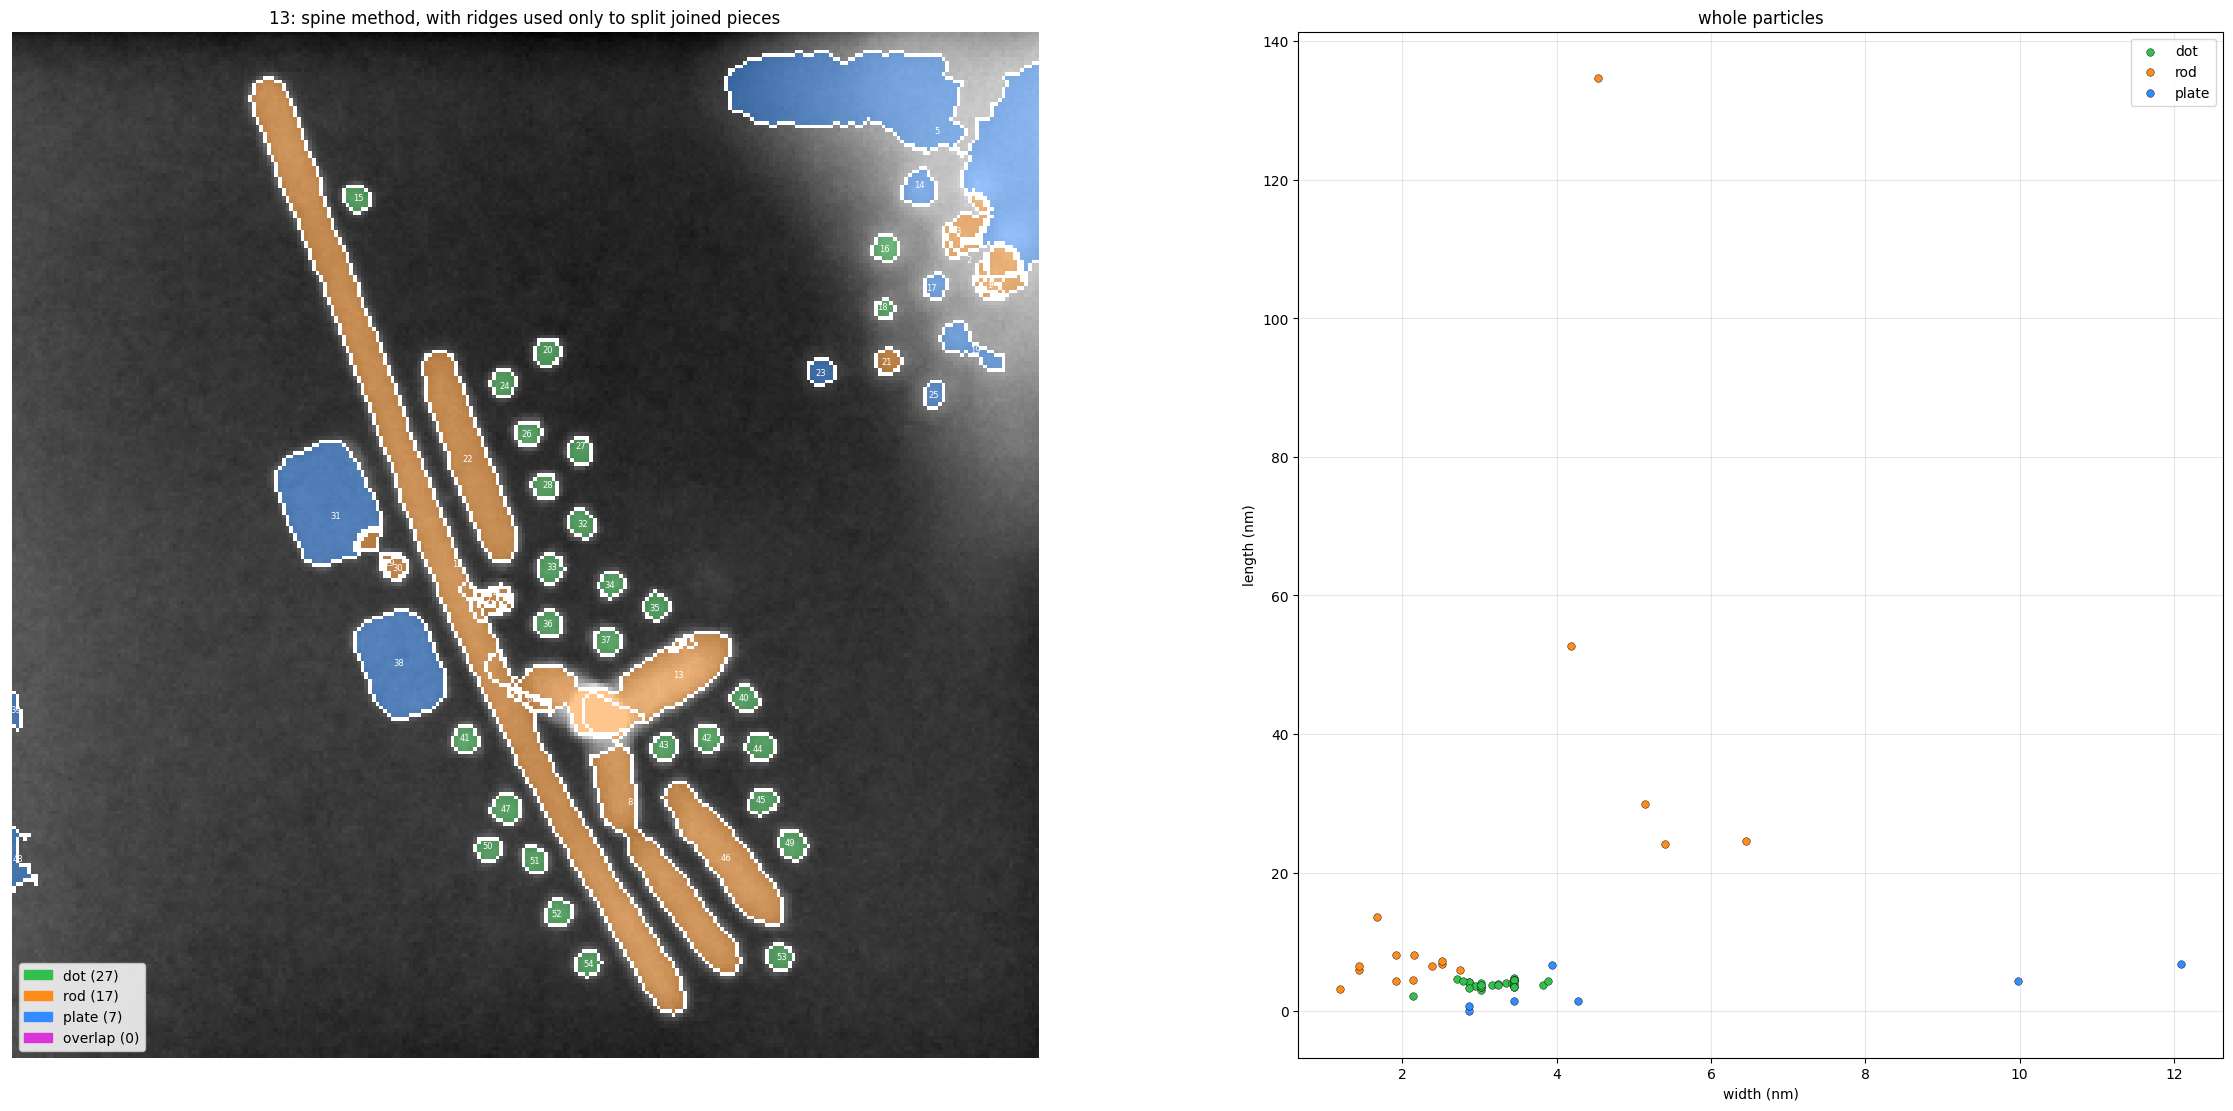

 id shape  length_nm  width_nm  thickness_nm  h_over_r  area_nm2      x      y  touches_edge
 32   dot       4.80      3.45          3.41      1.03     12.11 152.00 131.00         False
 27   dot       4.67      2.70          3.35      1.24     10.74 151.40 110.00         False
 35   dot       4.52      3.45          3.32      0.99     10.97 171.00 153.33         False
 44   dot       4.52      3.45          3.40      0.99     13.02 198.67 191.00         False
 49   dot       4.52      3.45          3.95      1.15     13.02 207.33 216.00         False
 37   dot       4.40      3.45          3.85      1.16     12.11 158.00 162.00         False
 47   dot       4.36      3.88          3.73      0.96     13.94 131.50 207.00         False
 28   dot       4.30      2.79          3.51      1.26     10.51 142.50 120.50         False
 15   dot       4.22      2.87          3.48      1.19     11.42  92.00  44.00         False
 26   dot       4.22      2.87          3.88      1.27     10.74 137.0

In [28]:
# C13. Back to the SPINE method (Cell 9); ridges (Cell 12) are used ONLY to split spine pieces that are branched (joined particles)
from skimage.segmentation import find_boundaries
import matplotlib.patches as mpatches
PRUNE_FACTOR = 1.5     # forks shorter than this x the half-width (rod-end corners, plate corners, noise) don't count as branches
PLATE13_HR   = 0.6     # a branched piece that is flat (median h/r below this) and has no strong ridge is ONE plate: kept whole
DOT_ASPECT13 = 2.0     # length / width below this = dot (real dots are often slightly elongated)
OVERLAP_HR13 = 1.4     # h/r above this (unsplit piece) = brighter than one particle: probably overlapping
IGNORE_BOX13 = None    # (top, bottom, left, right) in px: particles whose centre lies inside are left out, e.g. the bright cloud
COL13 = {'dot': (0.20, 0.75, 0.30), 'rod': (1.00, 0.55, 0.10), 'plate': (0.20, 0.55, 1.00), 'overlap': (0.85, 0.20, 0.85)}

mask, dist, img = WHOLE_RES['mask'], WHOLE_RES['dist'], WHOLE_RES['img']
H, W = mask.shape; K8 = np.ones((3, 3), int)
skel = np.zeros((H, W), bool); skel[WHOLE_RES['ys'], WHOLE_RES['xs']] = True
hr_map = np.zeros((H, W), np.float32); hr_map[WHOLE_RES['ys'], WHOLE_RES['xs']] = WHOLE_RES['hr']

# 13a. spine pieces and their regions, exactly as in the spine method: every mask pixel goes to the nearest spine piece
sp_lab, n_sp = ndi.label(skel, structure=K8)
idx = ndi.distance_transform_edt(sp_lab == 0, return_indices=True)[1]
region_of = sp_lab[idx[0], idx[1]] * mask

def is_branched(piece):
    # trim every branch end by PRUNE_FACTOR x the half-width, then look for a junction (3+ neighbours)
    r = float(np.median(np.clip(dist[piece], 0.5, None))); s = piece.copy()
    for _ in range(int(np.ceil(PRUNE_FACTOR * r))):
        nb = ndi.convolve(s.astype(int), K8, mode='constant') - 1
        ends = s & (nb <= 1)
        if not ends.any() or ends.sum() == s.sum(): break
        s &= ~ends
    nb = ndi.convolve(s.astype(int), K8, mode='constant') - 1
    return bool((s & (nb >= 3)).any())

def describe(sp_pix, reg, kind=None):
    rr = np.clip(dist[sp_pix[:, 0], sp_pix[:, 1]], 0.5, None); hrv = float(np.median(hr_map[sp_pix[:, 0], sp_pix[:, 1]]))
    flat = hrv < PLATE13_HR
    width = 2 * rr.max() if flat else 2 * np.median(rr)
    length = np.hypot(np.ptp(sp_pix[:, 1]), np.ptp(sp_pix[:, 0])) + (0 if flat else width)
    if kind is None:
        kind = 'plate' if flat else 'overlap' if hrv > OVERLAP_HR13 else 'rod' if length / width >= DOT_ASPECT13 else 'dot'
    return dict(shape=kind, mask=reg, length=length, width=width, thick=float(2 * np.median(hr_map[sp_pix[:, 0], sp_pix[:, 1]] * rr)),
                hr=hrv, y=sp_pix[:, 0].mean(), x=sp_pix[:, 1].mean())

parts13, n_split, n_kept = [], 0, 0
for i in range(1, n_sp + 1):
    piece = sp_lab == i; reg = region_of == i
    if not reg.any(): continue
    sp_pix = np.argwhere(piece)
    flat_piece = np.median(hr_map[piece]) < PLATE13_HR and not (strong & reg).any()
    if not is_branched(piece) or flat_piece:                    # 13b. one particle: keep the spine result as it is
        parts13.append(describe(sp_pix, reg)); n_kept += 1; continue
    # 13c. a branched (joined) piece: split it with the Cell 12 ridge pieces that lie inside it
    n_split += 1
    loc = [p for p in pieces if reg[tuple(p['pix'].astype(int).T)].mean() > 0.5]
    if not loc: parts13.append(describe(sp_pix, reg)); continue
    par_l = list(range(len(loc)))
    def f_(k):
        while par_l[k] != k: par_l[k] = par_l[par_l[k]]; k = par_l[k]
        return k
    own = np.full((H, W), -1, np.int32)
    for k, p in enumerate(loc): own[tuple(p['pix'].astype(int).T)] = k
    for k, p in enumerate(loc):                                 # touching pieces in neighbouring angle channels: one rod
        nbm = ndi.binary_dilation(own == k, K8, iterations=2)
        for j in set(np.unique(own[nbm])) - {-1, k}:
            if min(abs(p['a'] - loc[j]['a']), N_ANG12 - abs(p['a'] - loc[j]['a'])) <= 1: par_l[f_(k)] = f_(j)
    for k, p in enumerate(loc):                                 # pieces continuing in a line (through a crossing): one rod
        for j in range(k + 1, len(loc)):
            q = loc[j]
            if ang_between(p['d'], q['d']) > JOIN_DEG: continue
            gap = min(np.hypot(*(e - f)) for e in (p['e0'], p['e1']) for f in (q['e0'], q['e1']))
            if gap > JOIN_GAP: continue
            dm = p['d'] + np.sign(np.dot(p['d'], q['d'])) * q['d']; dm /= np.hypot(*dm); dv = q['c'] - p['c']
            if abs(dm[0] * dv[1] - dm[1] * dv[0]) < JOIN_OFFSET: par_l[f_(k)] = f_(j)
    groups = {}
    for k in range(len(loc)): groups.setdefault(f_(k), []).append(k)
    sub = []
    for g in groups.values():
        rp = np.concatenate([loc[k]['pix'] for k in g])
        if len(rp) < MIN_ROD_PX: continue
        c = rp.mean(0); _, _, vt = np.linalg.svd(rp - c, full_matrices=False); d = vt[0]; theta = np.arctan2(d[0], d[1])
        smp = rp[np.linspace(0, len(rp) - 1, min(len(rp), 40)).astype(int)]
        hw = np.nanmedian([half_width(py, px, theta) for py, px in smp])
        rimg = np.zeros((H, W), bool); rimg[tuple(rp.astype(int).T)] = True
        m = (ndi.distance_transform_edt(~rimg) <= hw) & reg
        clean = ~crossing_px[tuple(rp.astype(int).T)]
        pk = sig[tuple(rp.astype(int).T)][clean] if clean.any() else sig[tuple(rp.astype(int).T)]
        sub.append(dict(shape='rod', mask=m, length=float(np.ptp((rp - c) @ d) + 2 * hw), width=float(2 * hw),
                        thick=float(np.median(pk) / amp), hr=float(np.median(pk) / amp / max(2 * hw, 1e-6) * 2), y=c[0], x=c[1]))
    # whatever the rods don't cover in this region: give it to the nearest rod if close, else keep it as its own spine particle(s)
    covered = np.any([s_['mask'] for s_ in sub], axis=0) if sub else np.zeros((H, W), bool)
    rest = reg & ~covered
    if sub and rest.any():
        labs = np.zeros((H, W), np.int32)
        for k, s_ in enumerate(sub, 1): labs[s_['mask'] & (labs == 0)] = k
        dd, ii = ndi.distance_transform_edt(labs == 0, return_indices=True); near = labs[ii[0], ii[1]]
        for k, s_ in enumerate(sub, 1): s_['mask'] |= rest & (near == k) & (dd <= 3)
        rest &= dd > 3
    for r_lab in range(1, ndi.label(rest)[1] + 1) if rest.any() else []:    # leftover blobs (e.g. a dot touching a rod)
        rl = ndi.label(rest)[0] == r_lab; sp_here = np.argwhere(piece & rl)
        if rl.sum() >= 12 and len(sp_here): sub.append(describe(sp_here, rl))
    parts13.extend(sub if sub else [describe(sp_pix, reg)])

# leave out particles inside the ignore box
if IGNORE_BOX13 is not None:
    t0, b0, l0, r0 = IGNORE_BOX13
    parts13 = [p for p in parts13 if not (t0 <= p['y'] < b0 and l0 <= p['x'] < r0)]
# table
rows = []
for k, p in enumerate(parts13, 1):
    m = p['mask']
    if p['shape'] == 'rod' and p['length'] / max(p['width'], 1e-6) < DOT_ASPECT13: p['shape'] = 'dot'
    rows.append(dict(id=k, shape=p['shape'], length_nm=p['length'] * NM_PER_PX, width_nm=p['width'] * NM_PER_PX,
                     thickness_nm=p['thick'] * NM_PER_PX, h_over_r=p['hr'], area_nm2=m.sum() * NM_PER_PX**2, x=p['x'], y=p['y'],
                     touches_edge=bool(m[[0, -1]].any() or m[:, [0, -1]].any())))
FINAL13 = pd.DataFrame(rows); F13w = FINAL13[~FINAL13.touches_edge]
print(f"{n_sp} spine pieces: {n_kept} kept as single particles, {n_split} branched ones split with ridges")
print(f"{len(FINAL13)} particles ({len(F13w)} not touching the edge):", F13w['shape'].value_counts().to_dict())

# overlay
rgb = np.dstack([(img - img.min()) / (np.percentile(img, 99.8) - img.min() + 1e-9)] * 3).clip(0, 1)
paint = np.zeros((H, W, 3)); cnt = np.zeros((H, W))
for p in parts13: paint[p['mask']] += COL13[p['shape']]; cnt[p['mask']] += 1
out = rgb.copy(); hit = cnt > 0; out[hit] = 0.5 * rgb[hit] + 0.5 * np.clip(paint[hit] / cnt[hit, None], 0, 1)
for p in parts13: out[find_boundaries(p['mask'], mode='inner')] = 1.0
fig, ax = plt.subplots(1, 2, figsize=(24, 11), constrained_layout=True, gridspec_kw=dict(width_ratios=[1.5, 1]))
ax[0].imshow(out)
if IGNORE_BOX13 is not None:
    ax[0].add_patch(plt.Rectangle((IGNORE_BOX13[2], IGNORE_BOX13[0]), IGNORE_BOX13[3] - IGNORE_BOX13[2], IGNORE_BOX13[1] - IGNORE_BOX13[0], fill=False, ec='r', ls='--'))
for _, p in FINAL13.iterrows(): ax[0].text(p.x, p.y, str(int(p.id)), color='w', fontsize=6, ha='center', va='center')
cnts = F13w['shape'].value_counts()
ax[0].legend(handles=[mpatches.Patch(color=c, label=f"{k} ({cnts.get(k, 0)})") for k, c in COL13.items()], loc='lower left', fontsize=10, framealpha=.85)
ax[0].set_title('13: spine method, with ridges used only to split joined pieces'); ax[0].axis('off')
for k, c in COL13.items():
    s = F13w[F13w['shape'] == k]
    if len(s): ax[1].scatter(s.width_nm, s.length_nm, s=30, color=c, label=k, edgecolor='k', lw=.3)
ax[1].set_xlabel('width (nm)'); ax[1].set_ylabel('length (nm)'); ax[1].legend(); ax[1].grid(alpha=.3); ax[1].set_title('whole particles')
plt.show()
print(F13w.sort_values(['shape', 'length_nm'], ascending=[True, False]).round(2).to_string(index=False))